# 05 · Visualizaciones

Todas las figuras siguen la misma plantilla editorial propia (`src/charts.py`):

- fondo azul pizarra; título **alineado a la izquierda** con barra de acento y subtítulo con periodo y universo;
- ejes abiertos (izquierdo e inferior), **líneas finas** y cuadrícula tenue;
- **leyenda** y recuadros **«¿Cómo leer?»** o **«Datos clave»** que explican cada indicador en lenguaje llano;
- **pie** con fuente y un dato agregado (mediana, total o rango).

Los mapas añaden océano, países vecinos (Natural Earth), contornos estatales y **barra de
color** con su unidad. Paleta validada para daltonismo y contraste sobre el fondo oscuro:
verde azulado `#1fa596` y coral `#e5683f`; gris para lo no concluyente.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
PROC = ROOT / "data/processed"
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
from datetime import date
from src import charts, geo
from src import visualization as viz
from src.basket import CANDIDATOS
from src.charts import b, n
names = CANDIDATOS.set_index("producto_normalizado").nombre.to_dict()
res = pd.read_csv(PROC / "resultados_analisis.csv", dtype={"cd_ensu": str})
meta = json.loads((ROOT / "data/metadata/resultados_meta.json").read_text(encoding="utf-8"))
meta["archivo_profeco"] = json.loads((ROOT / "data/metadata/profeco_manifest.json").read_text(encoding="utf-8"))["archivo"]
meta["generado"] = date.today().isoformat()
items = json.loads((ROOT / "data/metadata/canasta_parametros.json").read_text(encoding="utf-8"))["productos"]
SOCIAL, CHARTS = ROOT / "outputs/social", ROOT / "outputs/charts"
SOCIAL.mkdir(parents=True, exist_ok=True); CHARTS.mkdir(parents=True, exist_ok=True)

## 1. Gráfica principal: costo vs. seguridad (LinkedIn 1080×1350 y X 1600×900, PNG 200 DPI + SVG)

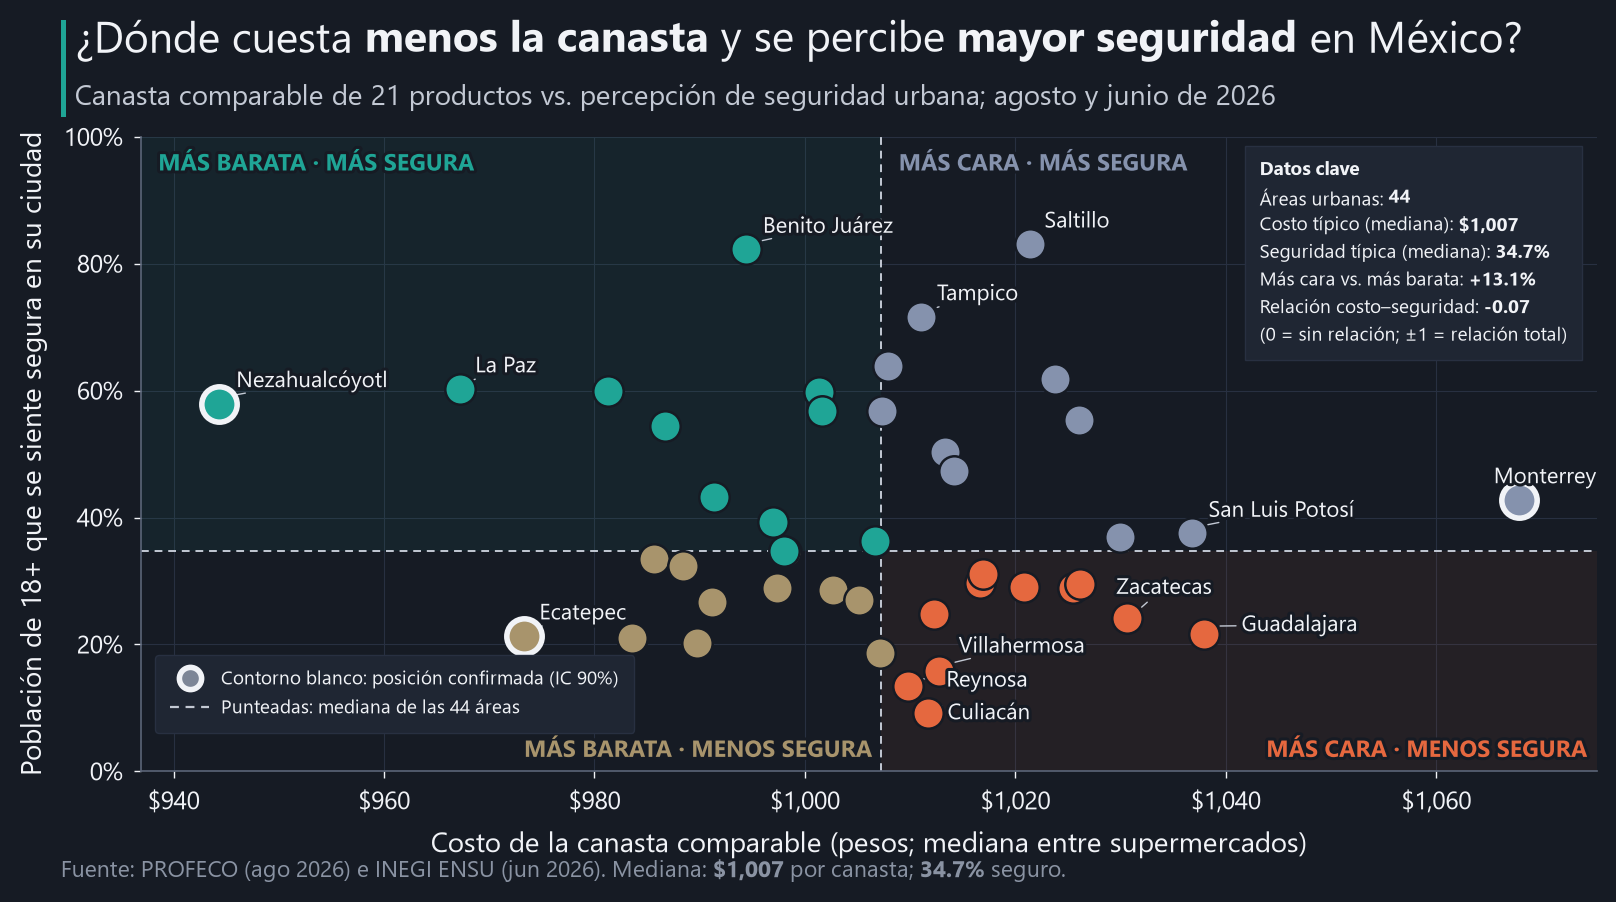

In [2]:
charts.scatter_quadrants(res, meta, SOCIAL / "grafica_principal_1600x900.png", (1600, 900)); plt.show()

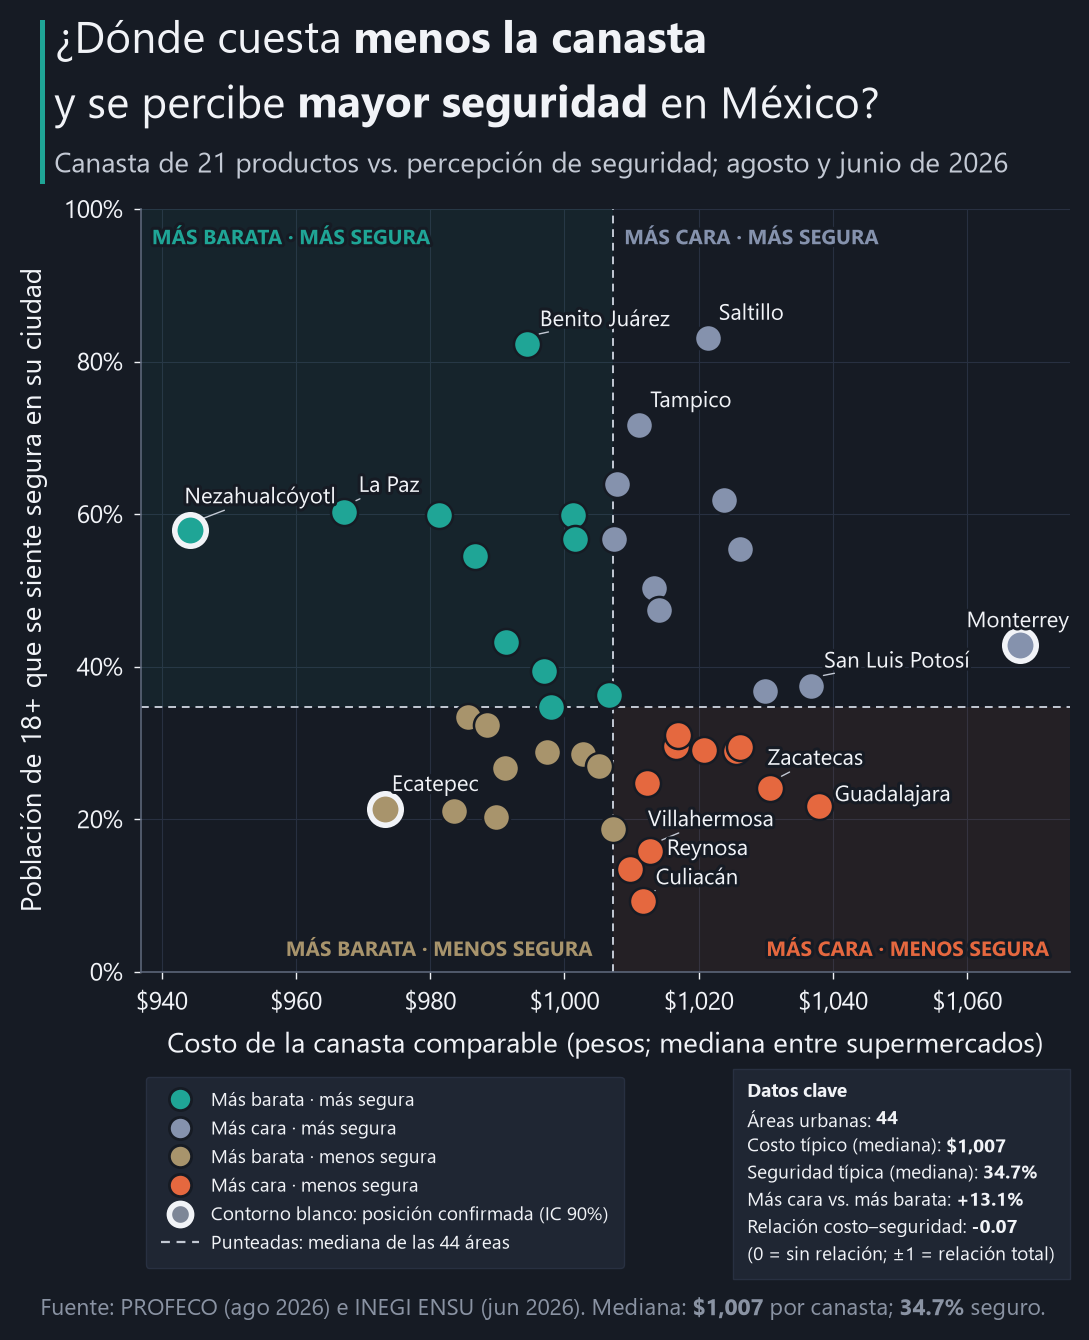

grafica_principal_1080x1350.png (1080, 1350)
grafica_principal_1600x900.png (1600, 900)


In [3]:
charts.scatter_quadrants(res, meta, SOCIAL / "grafica_principal_1080x1350.png", (1080, 1350)); plt.show()
from PIL import Image
for f in ["grafica_principal_1080x1350.png", "grafica_principal_1600x900.png"]:
    print(f, Image.open(SOCIAL / f).size)

## 2. Rankings con intervalos de confianza al 90 %

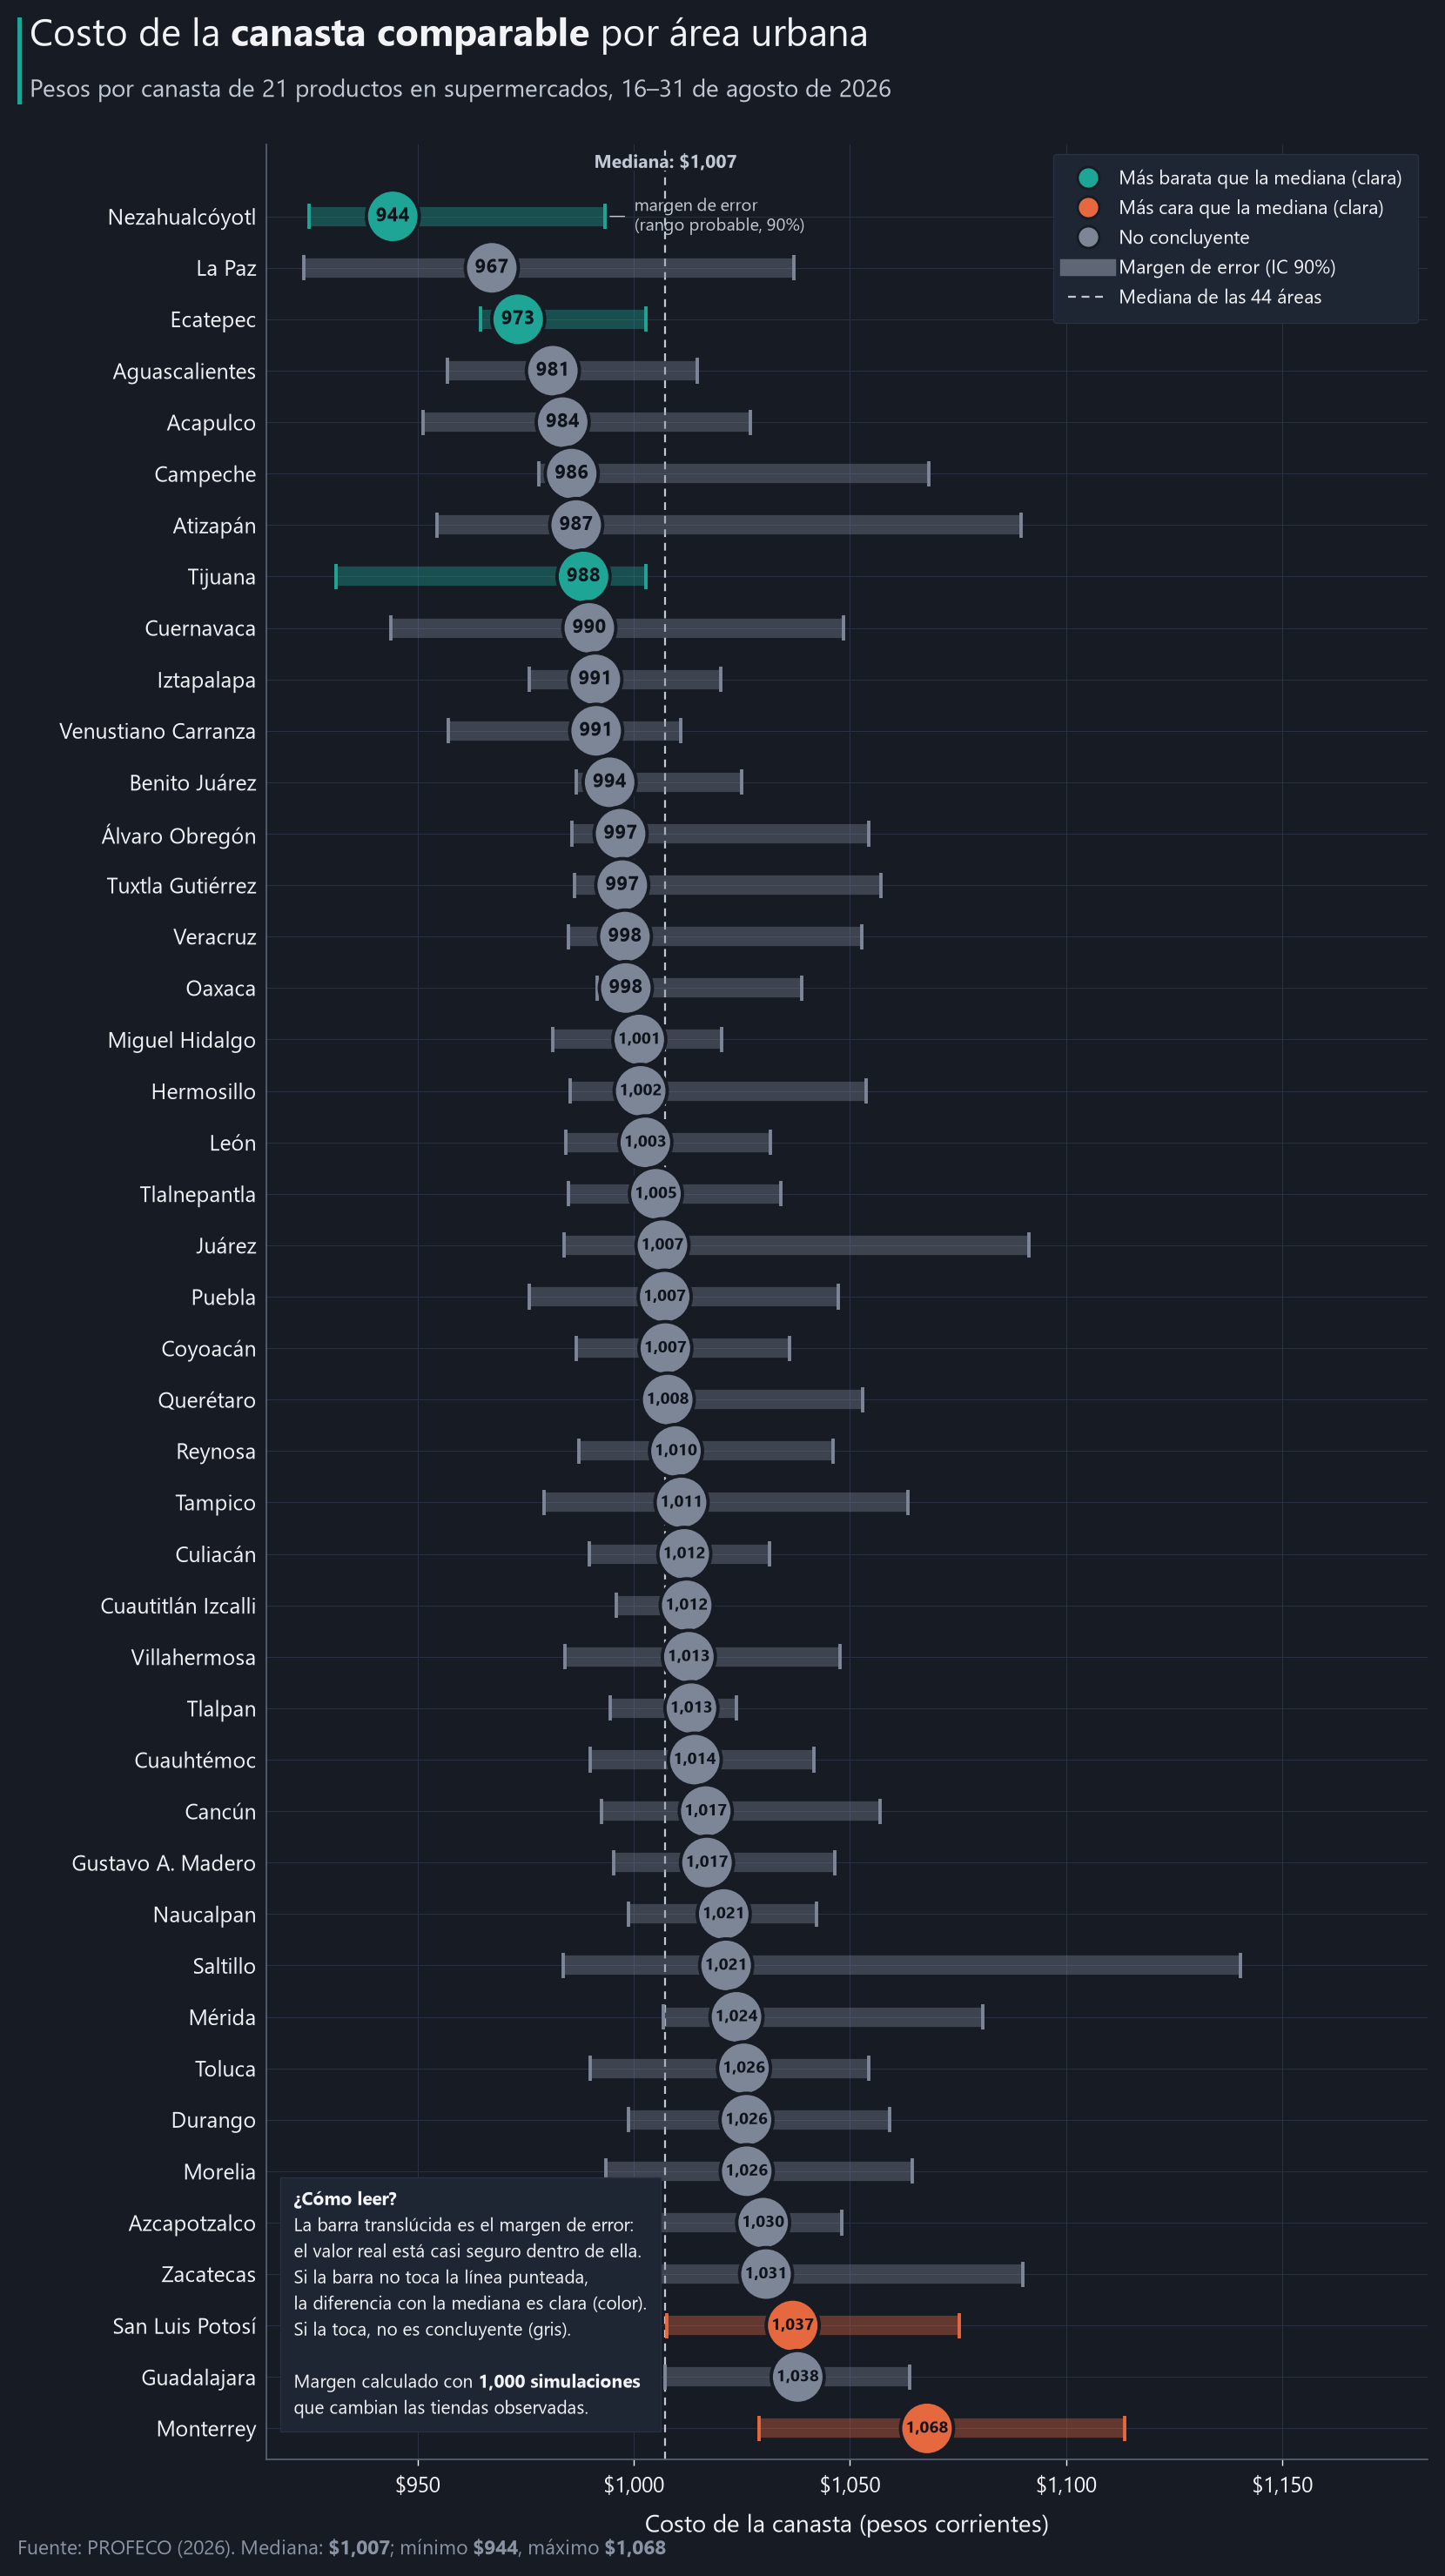

In [4]:
charts.ranking_cost(res, CHARTS / "02_ranking_costo_canasta.png"); plt.show()

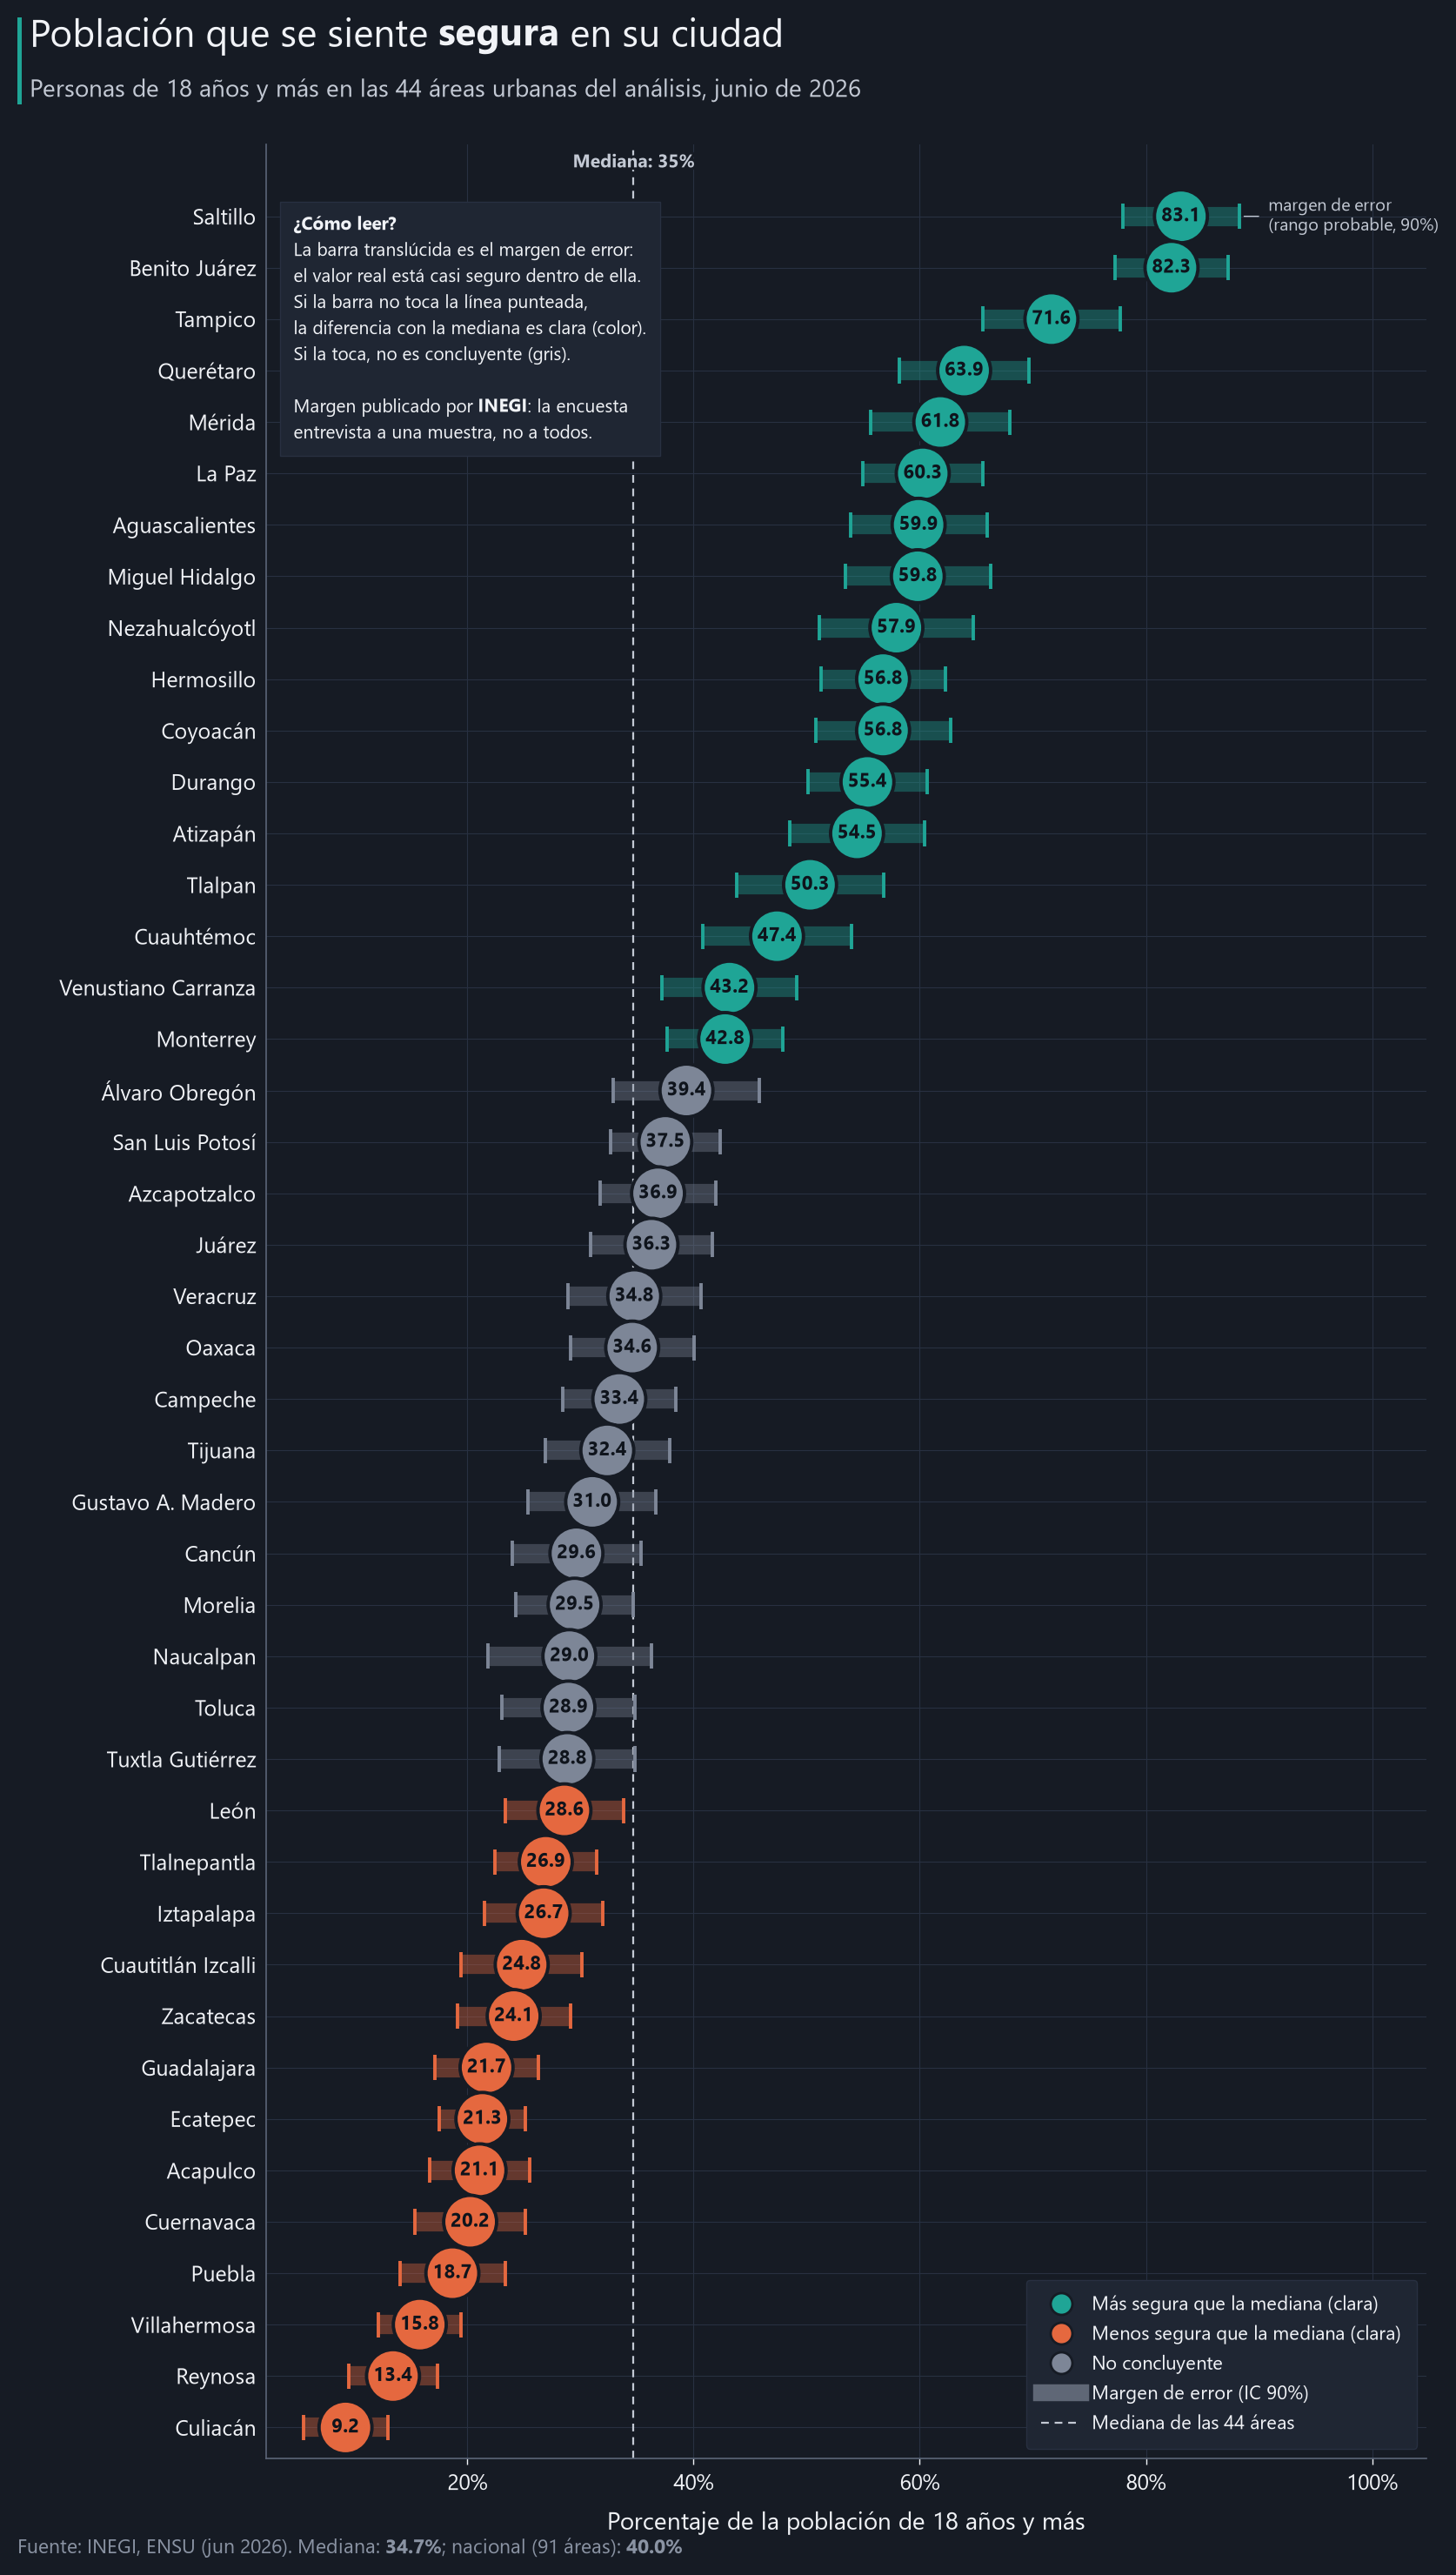

In [5]:
charts.ranking_security(res, CHARTS / "03_ranking_seguridad.png"); plt.show()

## 3. Productos: dispersión entre ciudades y distribución por tienda

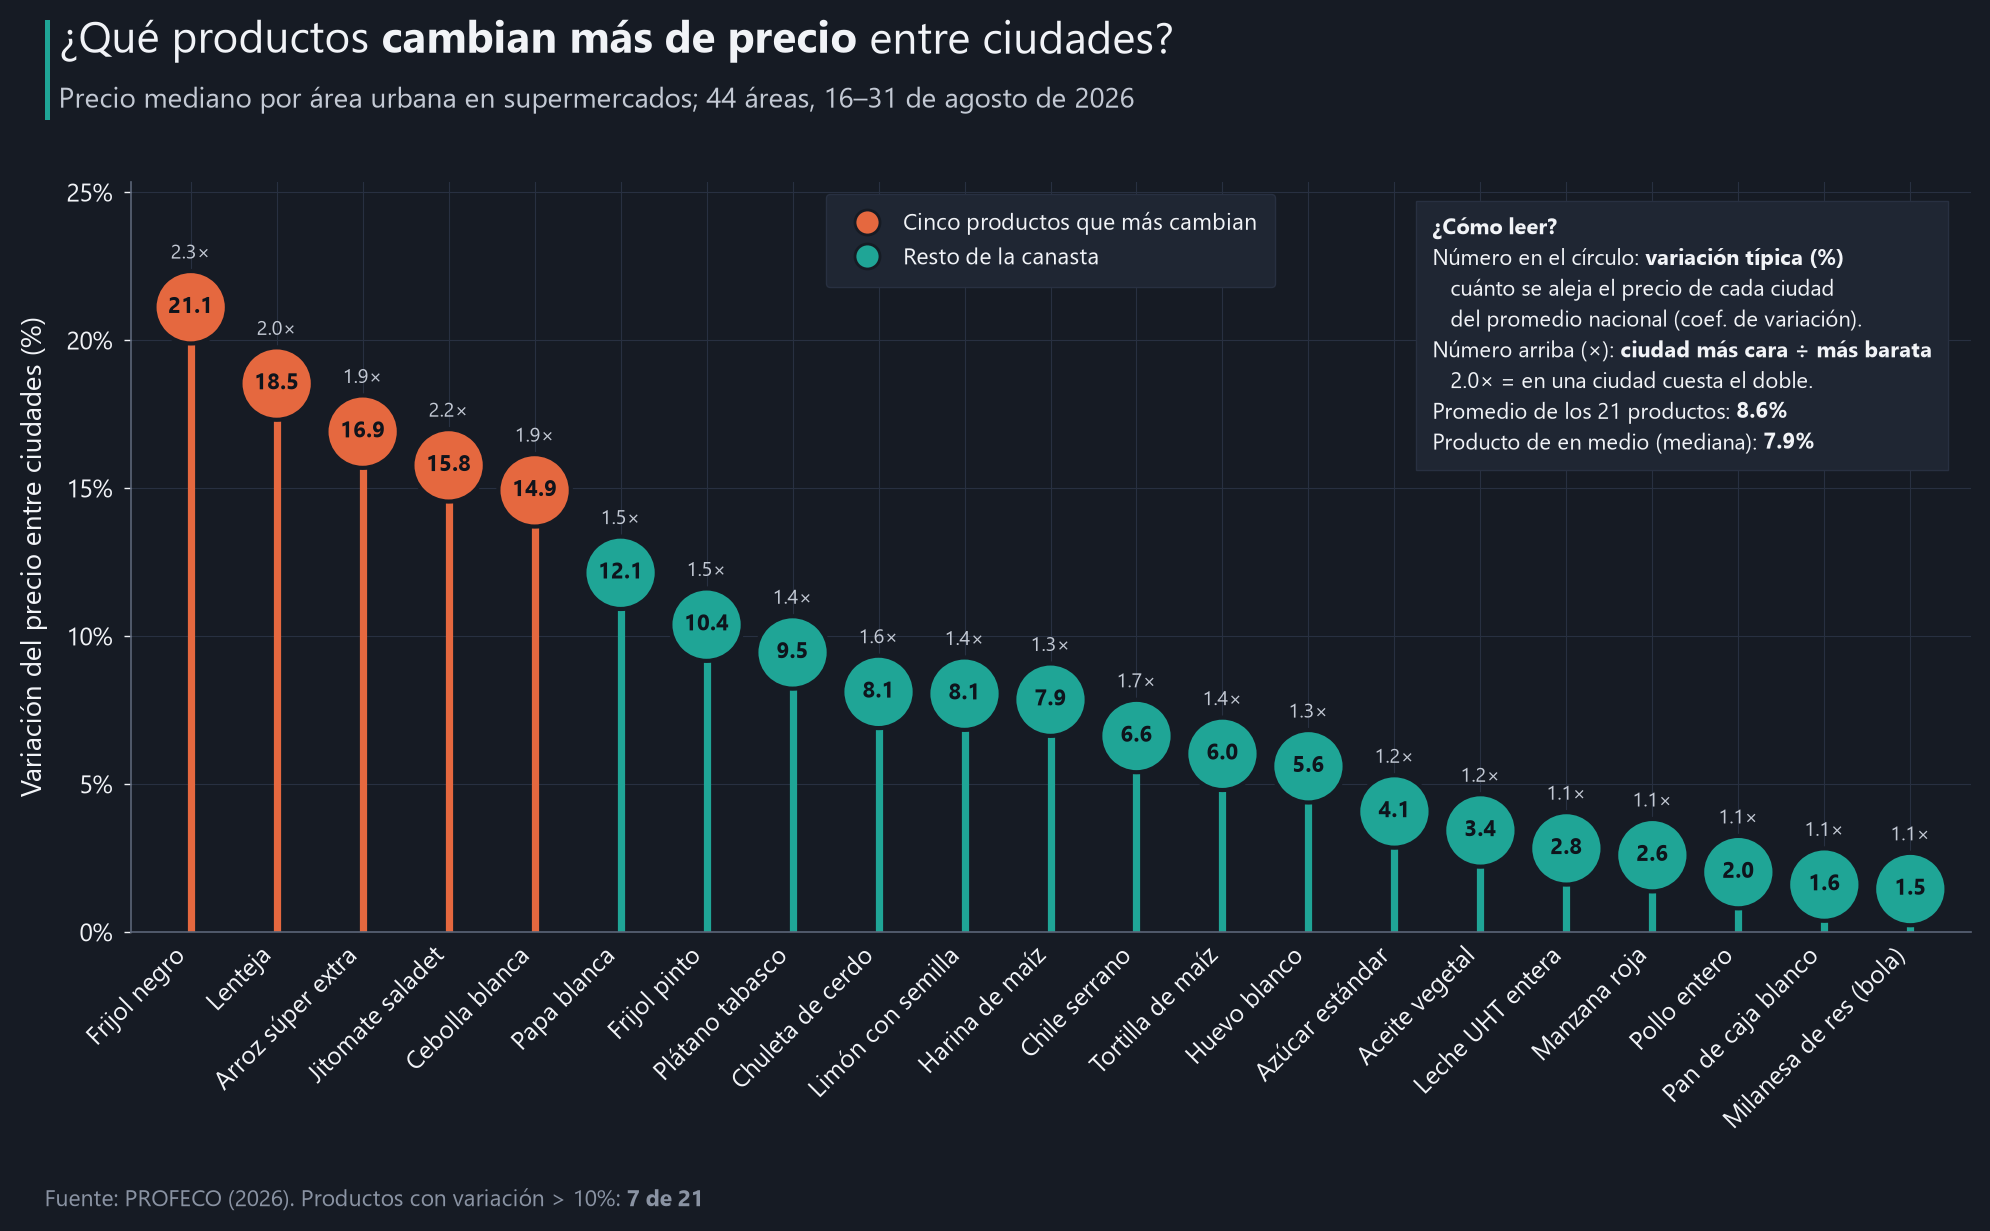

In [6]:
disp = pd.read_csv(PROC / "dispersion_productos.csv", index_col=0)
charts.dispersion_lollipop(disp, names, CHARTS / "04_dispersion_productos.png"); plt.show()

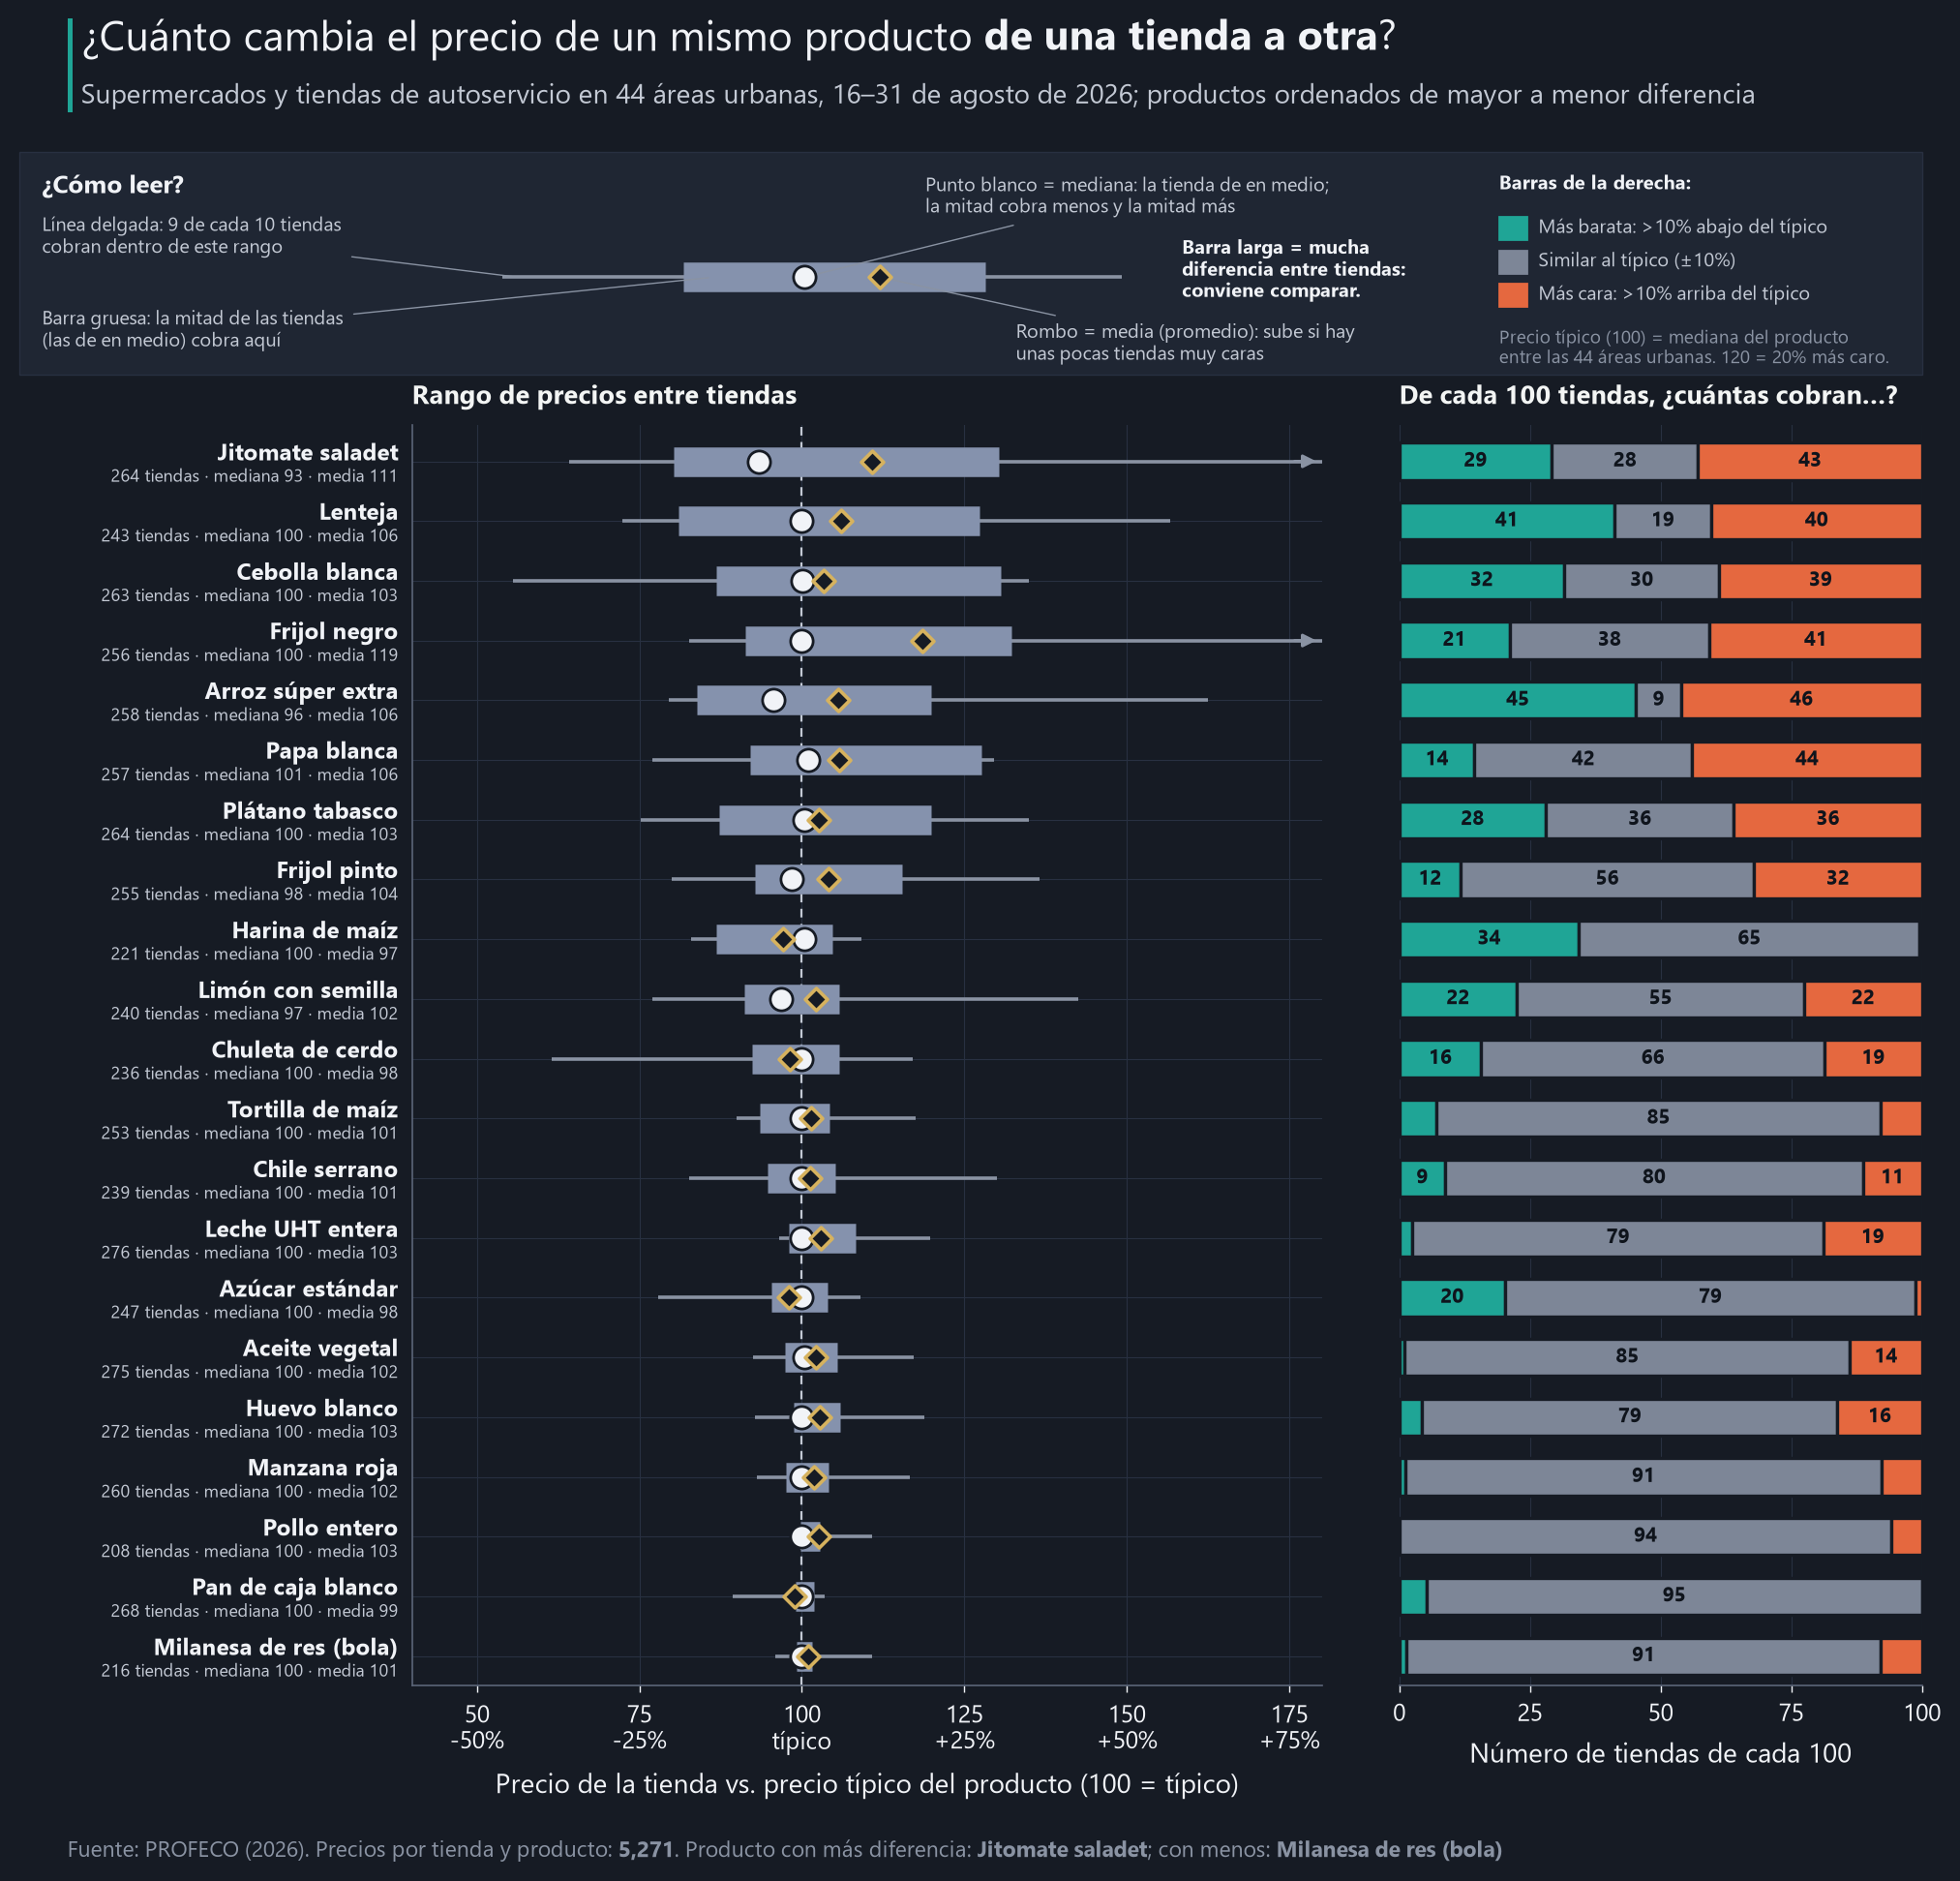

In [7]:
obs = pd.read_csv(PROC / "observaciones_canasta.csv")
prices = pd.read_csv(PROC / "precios_area_producto.csv", dtype={"cd_ensu": str})
obs = obs[obs.area_urbana_ensu.isin(res.area_urbana_ensu) & obs.producto_normalizado.isin(items)]
store = obs.groupby(["area_urbana_ensu", "establecimiento_id", "producto_normalizado"]).precio_unitario.median().reset_index()
ref = prices[prices.area_urbana_ensu.isin(res.area_urbana_ensu)].groupby("producto_normalizado").precio_mediana.median()
store["indice"] = store.precio_unitario / store.producto_normalizado.map(ref) * 100
charts.store_spread(store, names, disp.sort_values("cv_pct").index.tolist(), CHARTS / "05_distribucion_precios_tienda.png"); plt.show()

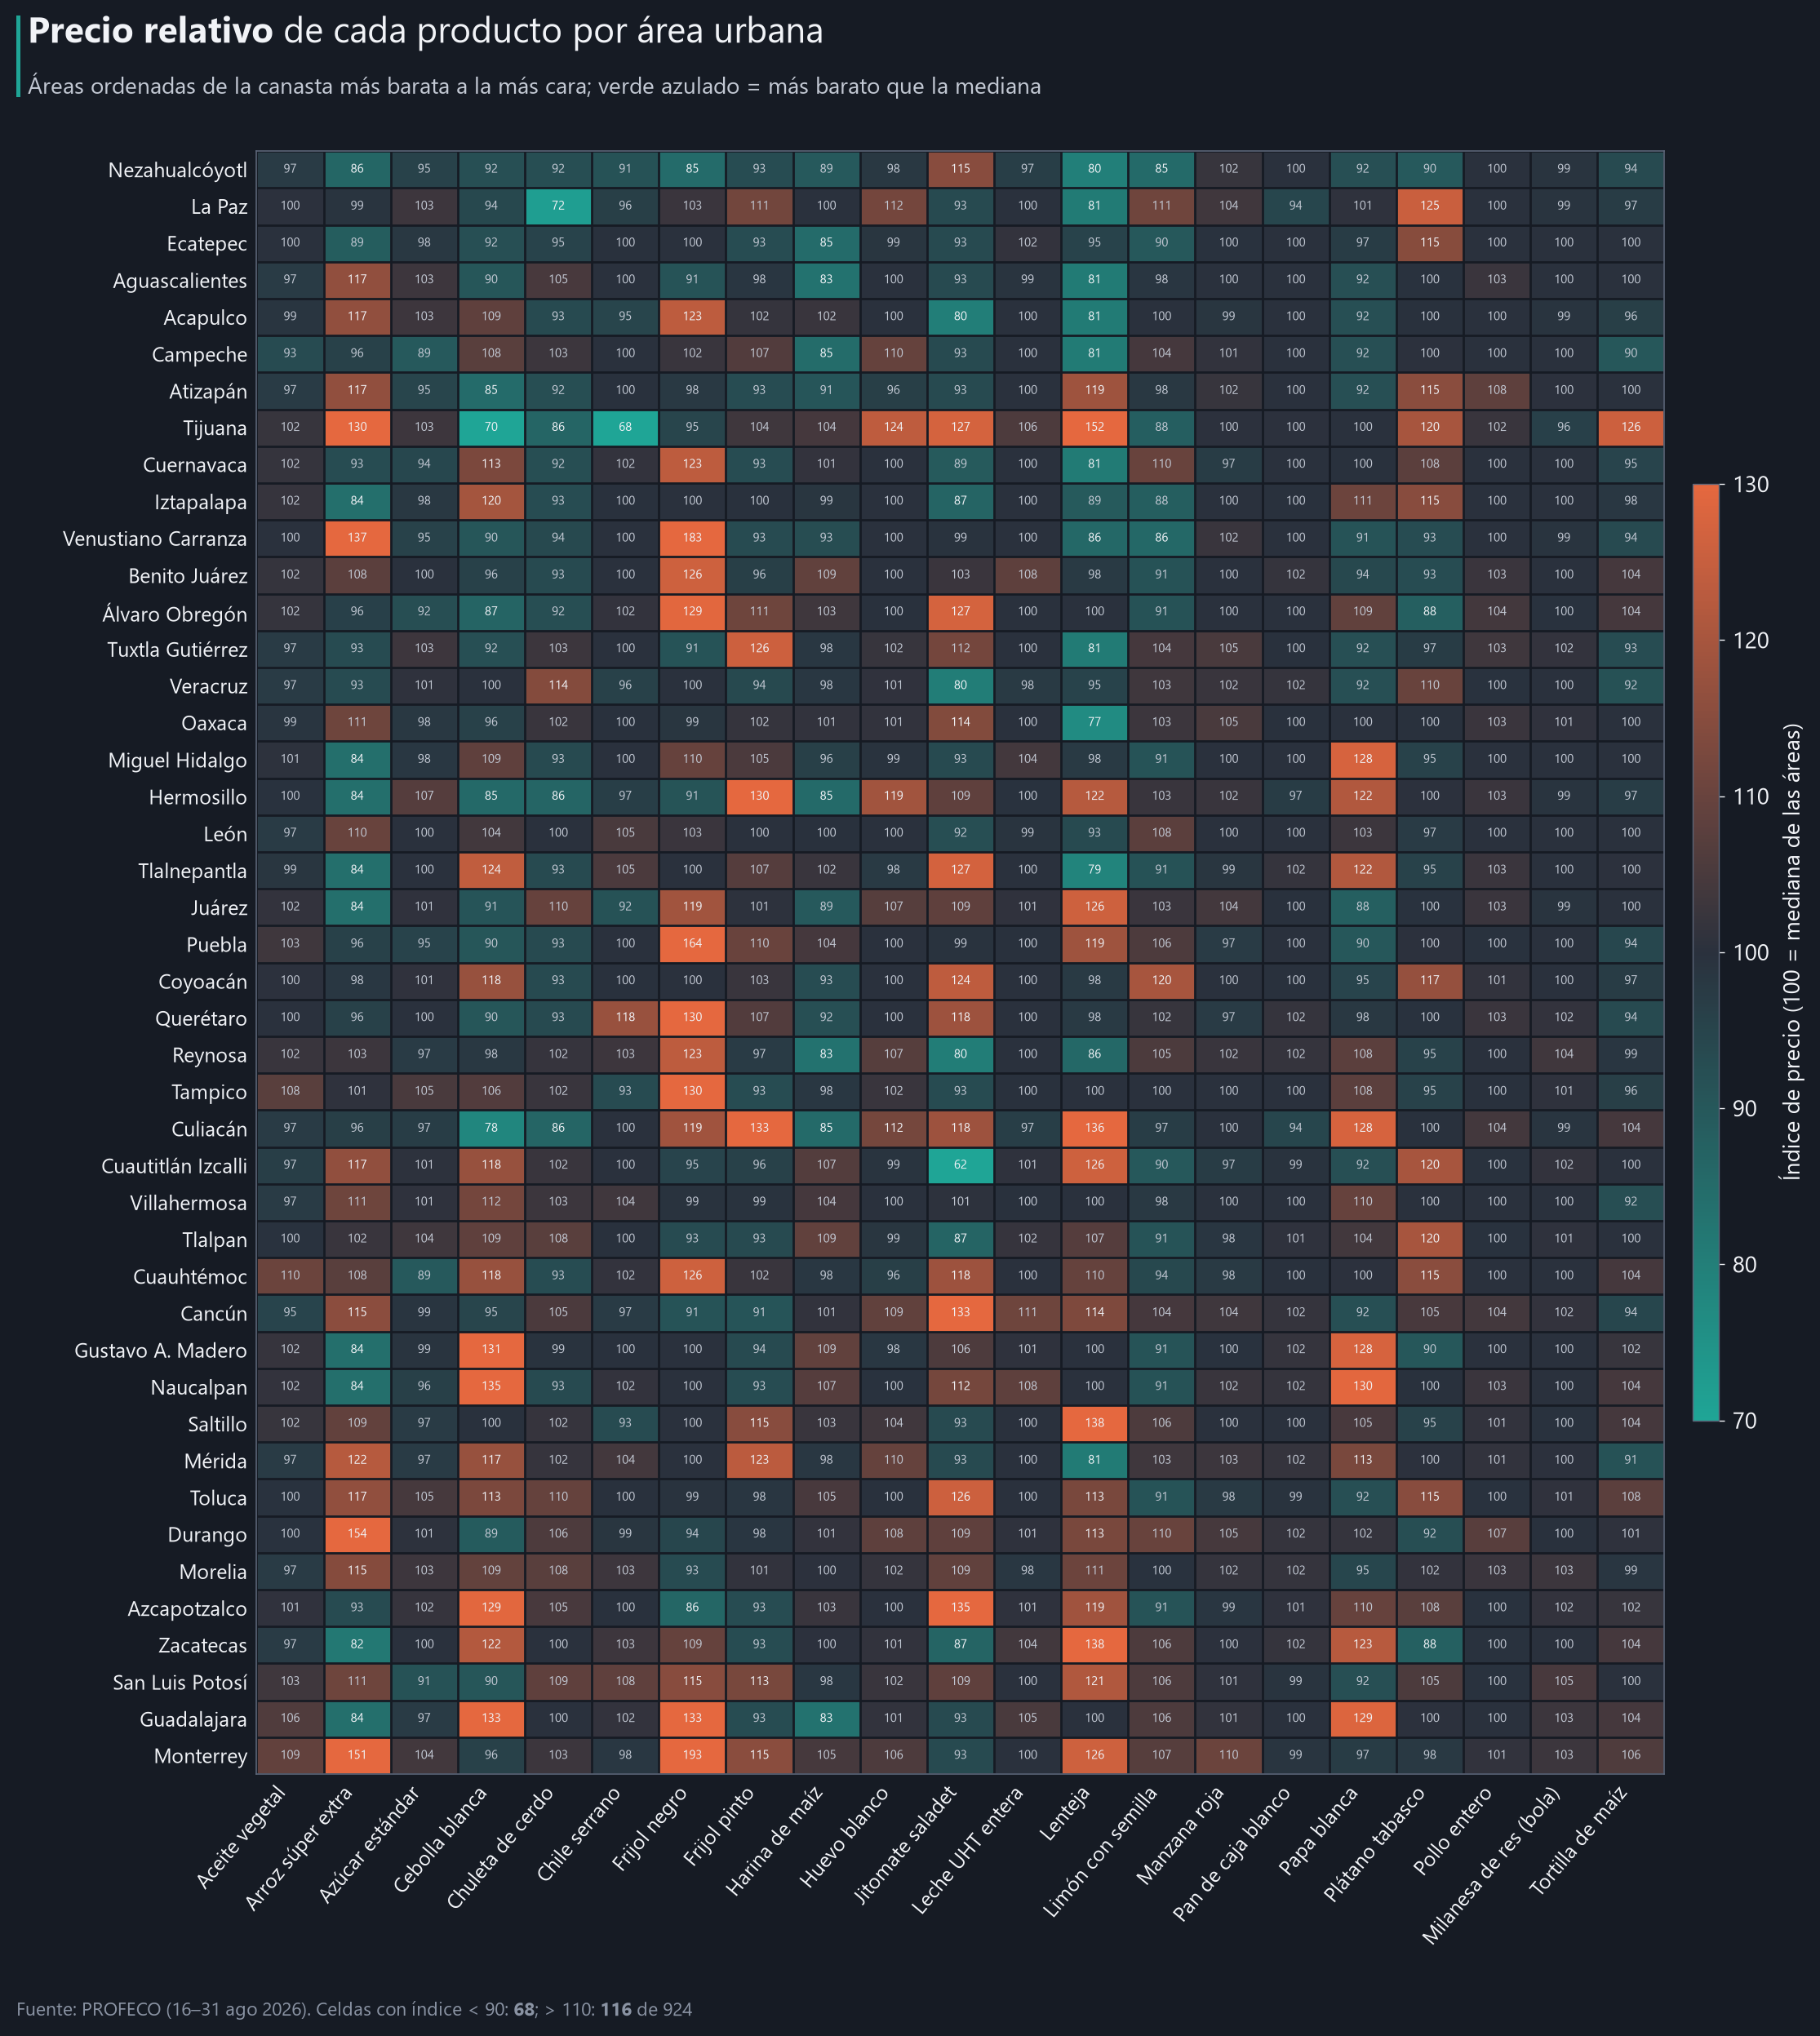

In [8]:
rel = pd.read_csv(PROC / "precios_relativos_area_producto.csv", index_col=0)
charts.relative_heatmap(rel, names, res.sort_values("costo_canasta").area_urbana_ensu, CHARTS / "06_heatmap_precio_relativo.png"); plt.show()

## 4. Cadenas y tabla de resultados

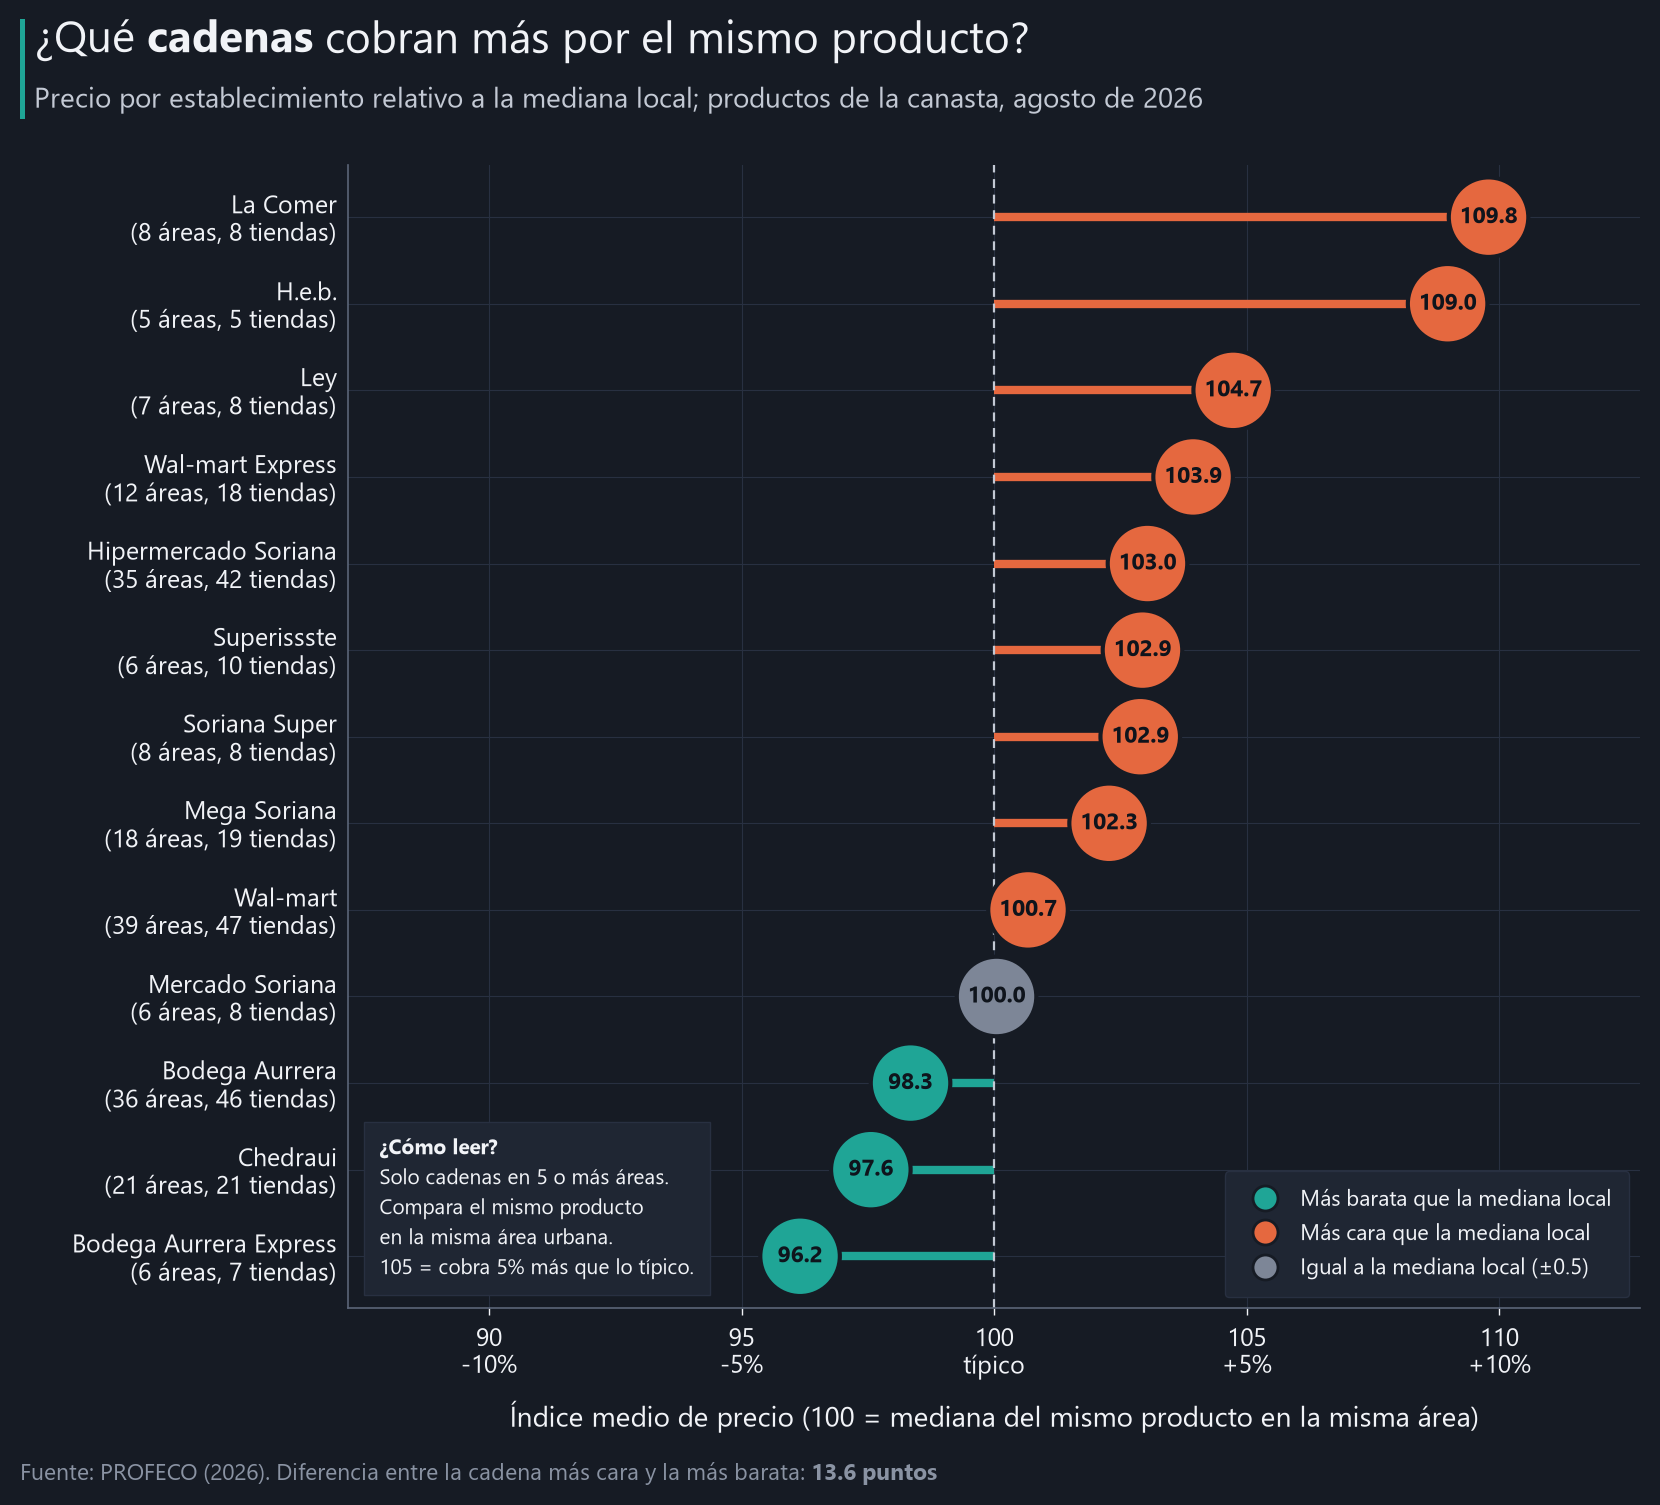

In [9]:
charts.chains_lollipop(pd.read_csv(PROC / "comparacion_cadenas.csv"), CHARTS / "07_comparacion_cadenas.png"); plt.show()

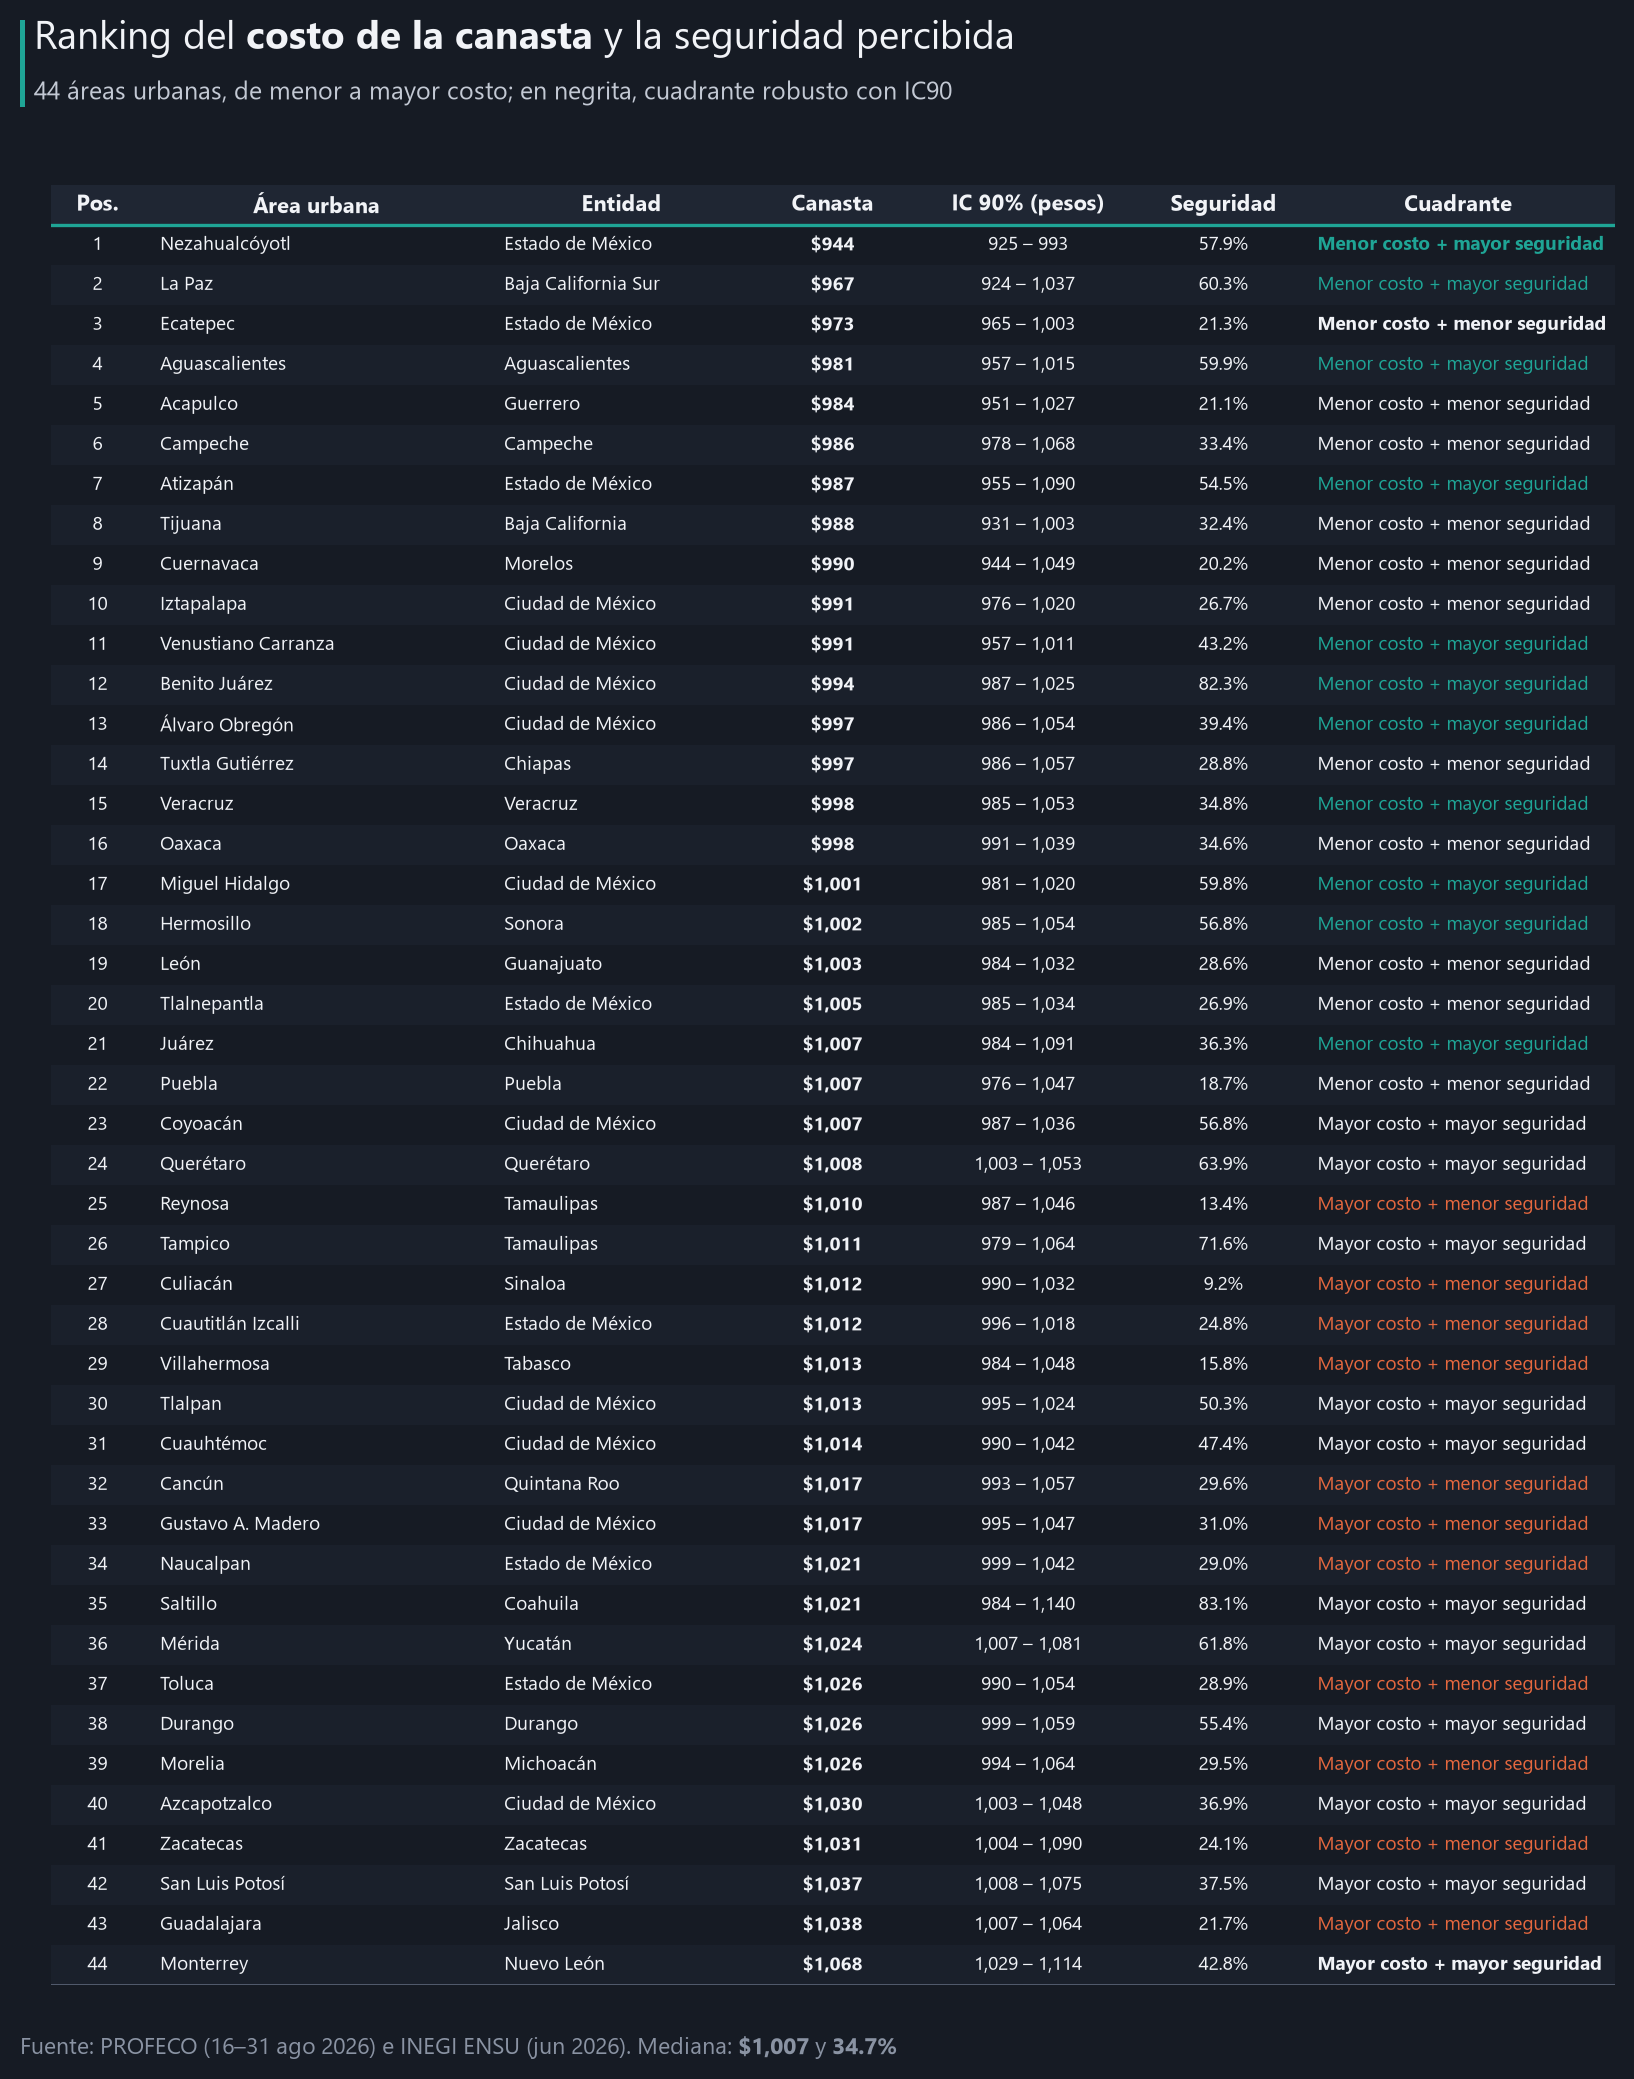

In [10]:
charts.ranking_table(res, CHARTS / "08_tabla_ranking.png"); plt.show()

## 5. Mapas de calor municipales

Límites: INEGI, Marco Geoestadístico 2024 (`00mun`, `00ent`), simplificados con `src/geo.py`.
Países vecinos: Natural Earth 1:50m. **Cada municipio toma el valor de su área urbana ENSU**
(costo y seguridad se estiman por área, no por municipio); en negro, municipios sin dato.
Recuadros: Valle de México, Guadalajara y Monterrey.

In [11]:
if not (ROOT / "data/processed/geo/municipios_lcc.json").exists():
    geo.build()
mun, ent = geo.load_projected("municipios"), geo.load_projected("entidades")
neighbors = charts.load_neighbors()
comp = pd.read_csv(PROC / "ensu_composicion_areas.csv", dtype={"CVE_ENT": str, "CVE_MUN": str, "CD": str})
comp["CVEGEO"] = comp.CVE_ENT + comp.CVE_MUN
ensu = pd.read_csv(PROC / "ensu_percepcion_areas.csv")
seg = comp.merge(ensu[["area_urbana_ensu", "seguridad_pct"]], on="area_urbana_ensu")
cost = comp.merge(res[["area_urbana_ensu", "costo_canasta"]], on="area_urbana_ensu")
assert seg.CVEGEO.isin({f["props"]["CVEGEO"] for f in mun}).all()
print(f"Seguridad: {len(seg)} municipios en {seg.area_urbana_ensu.nunique()} áreas; "
      f"canasta: {len(cost)} municipios en {cost.area_urbana_ensu.nunique()} áreas")
mun_by_id = {f["props"]["CVEGEO"]: f for f in mun}

def centroid(cvegeo):
    return max(mun_by_id[cvegeo]["rings"], key=len).mean(axis=0)

def principal(table):
    return table.sort_values("participacion_area_pct").drop_duplicates("area_urbana_ensu", keep="last")

def label_points(table, col, k=3):
    p = principal(table)
    pick = pd.concat([p.nsmallest(k, col), p.nlargest(k, col)])
    return [(tuple(centroid(r.CVEGEO) + [12000, 0]), viz.short_name(r.area_urbana_ensu)) for r in pick.itertuples()]

ZONAS = {"Valle de México": lambda t: t.CVE_ENT.isin(["09", "15"]) & ~t.area_urbana_ensu.eq("Toluca de Lerdo"),
         "Guadalajara": lambda t: t.CVE_ENT.eq("14") & ~t.area_urbana_ensu.eq("Puerto Vallarta"),
         "Monterrey": lambda t: t.CVE_ENT.eq("19")}

def insets(table):
    return {name: (comp[rule(comp)].CVEGEO.tolist(),
                   [(*centroid(r.CVEGEO), viz.short_name(r.area_urbana_ensu)) for r in principal(table[rule(table)]).itertuples()])
            for name, rule in ZONAS.items()}

Seguridad: 168 municipios en 90 áreas; canasta: 90 municipios en 44 áreas


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


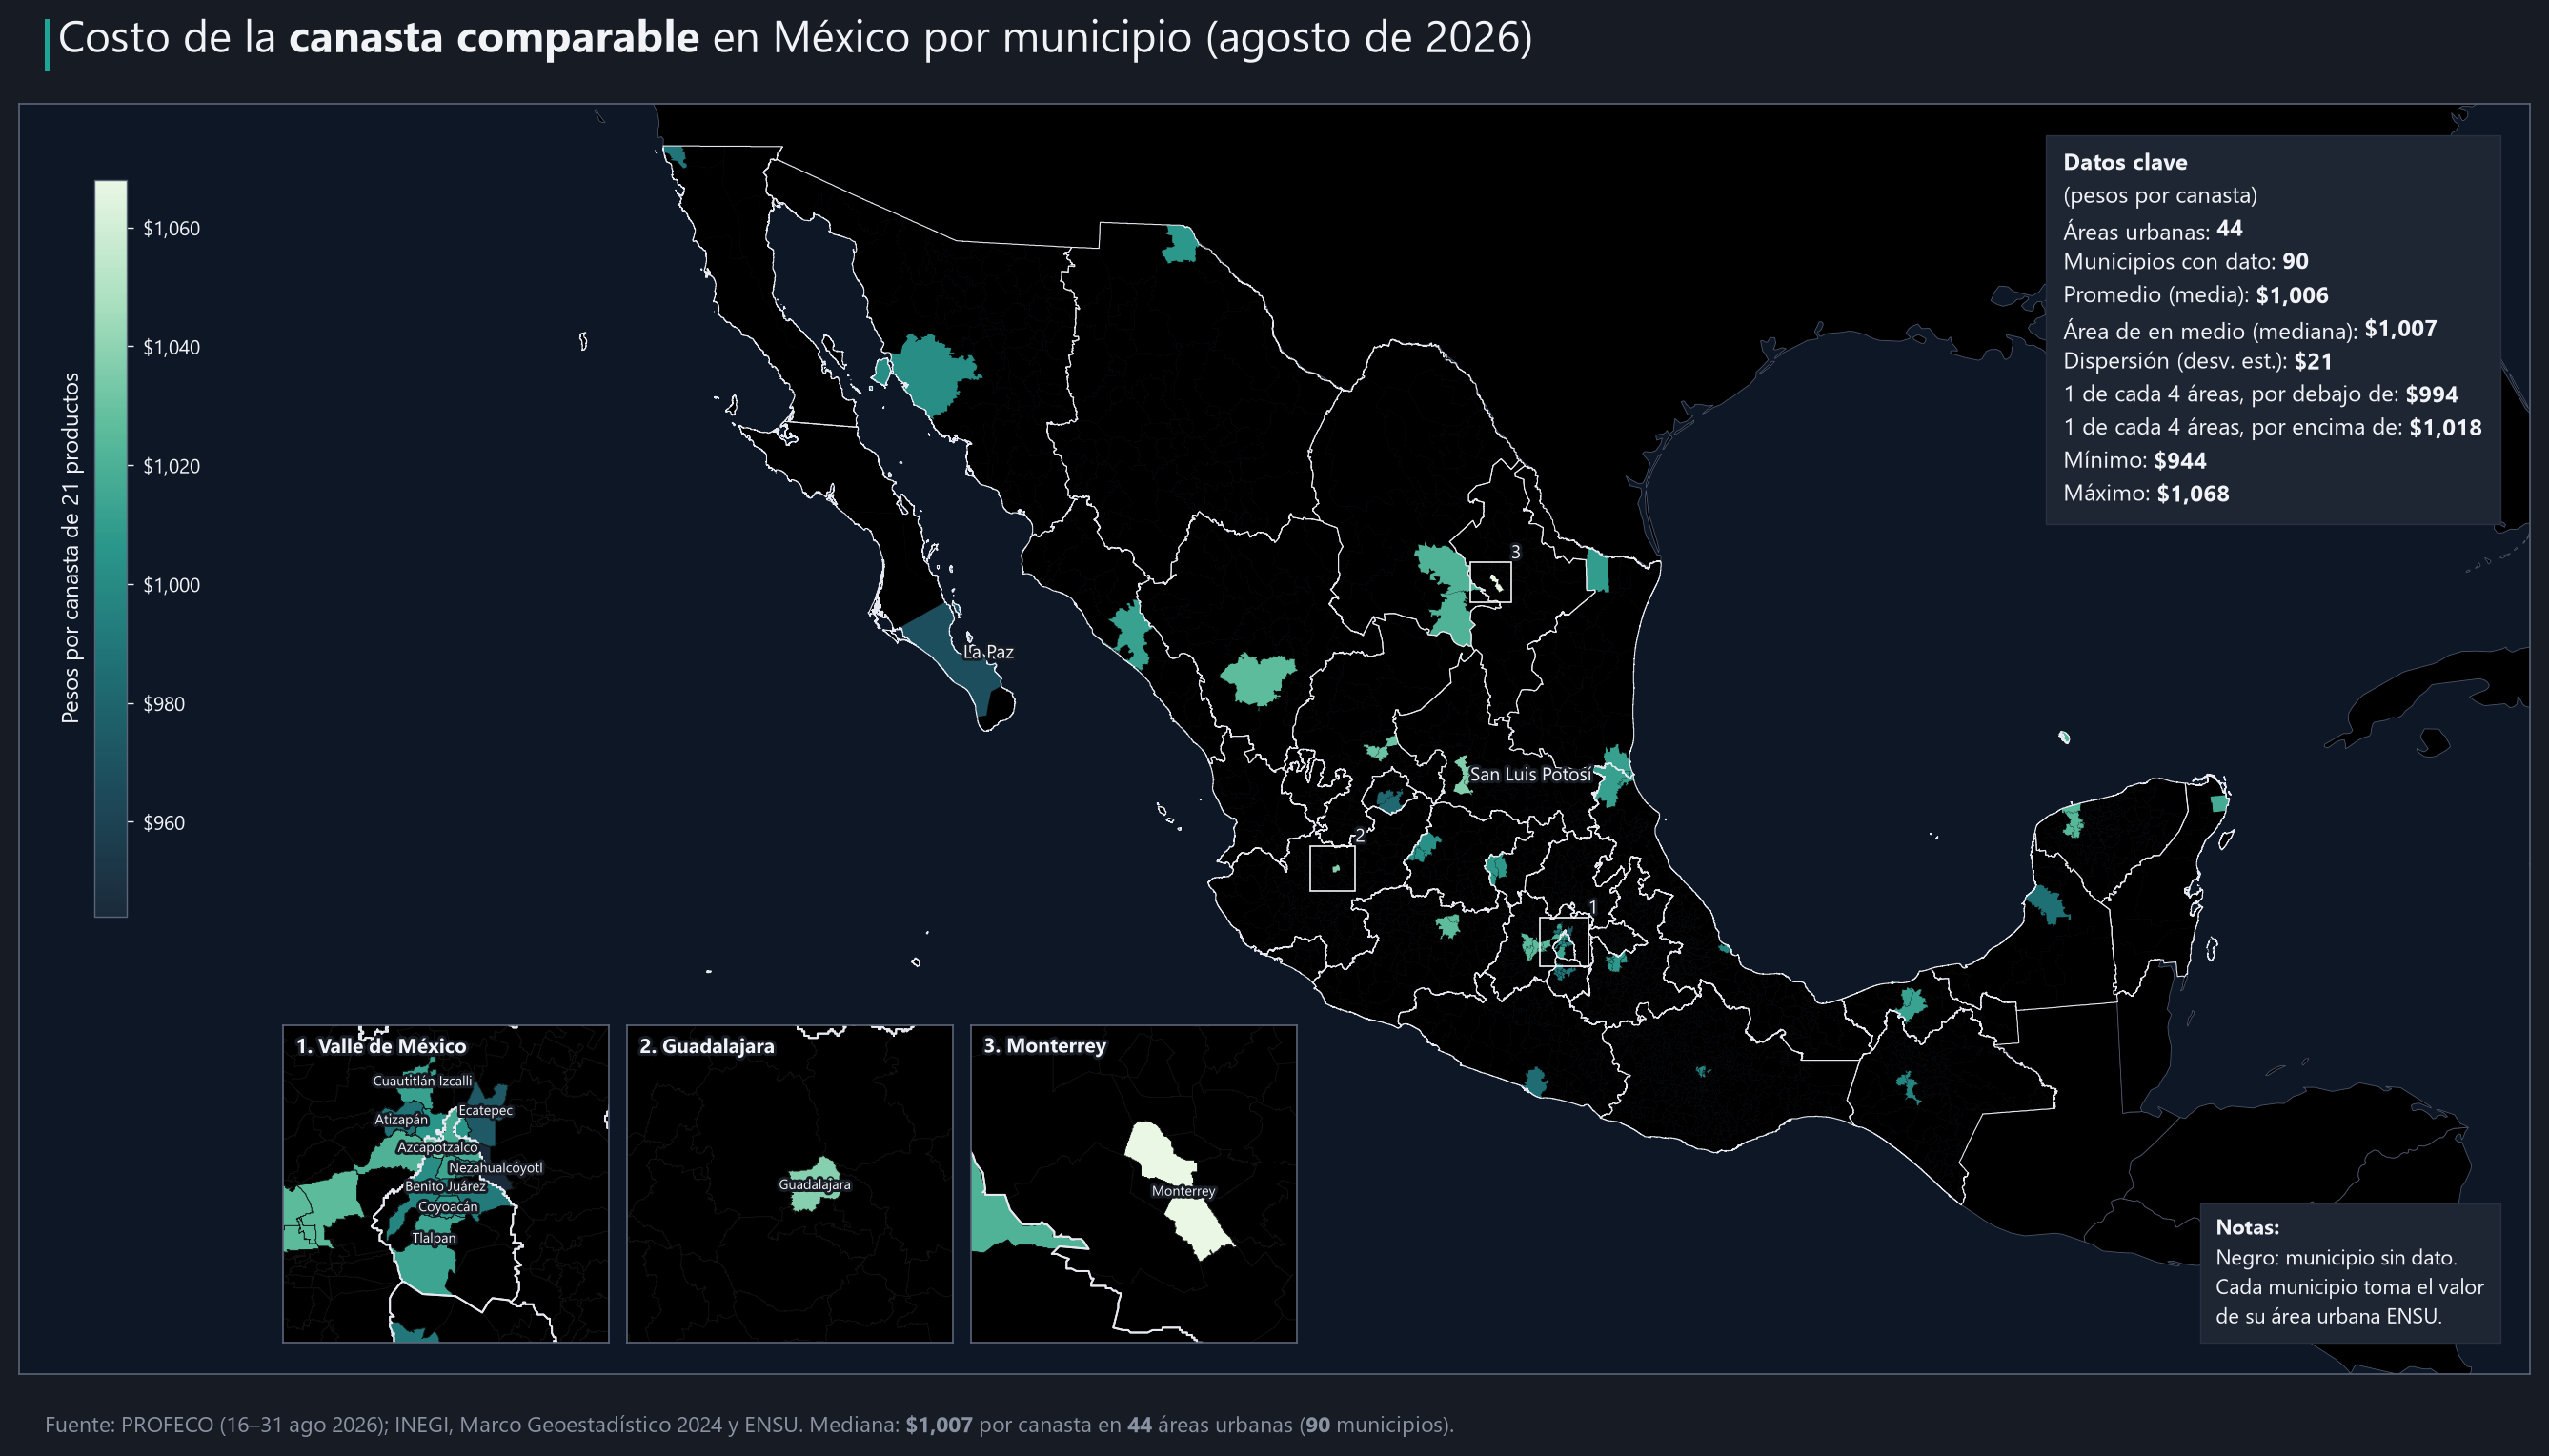

In [12]:
med = res.costo_canasta.median()
charts.municipal_map(
    mun, ent, neighbors, dict(zip(cost.CVEGEO, cost.costo_canasta)), res.costo_canasta,
    [n("Costo de la "), b("canasta comparable"), n(" en México por municipio (agosto de 2026)")],
    "pesos por canasta", "Pesos por canasta de 21 productos", lambda v: f"${v:,.0f}",
    [n("Fuente: PROFECO (16–31 ago 2026); INEGI, Marco Geoestadístico 2024 y ENSU. Mediana: "), b(f"${med:,.0f}"),
     n(" por canasta en "), b(f"{len(res)}"), n(" áreas urbanas ("), b(f"{len(cost)}"), n(" municipios).")],
    CHARTS / "09_mapa_municipal_costo.png", insets(cost), labels=label_points(cost, "costo_canasta"),
    n_mun=len(cost), note_lines=["Negro: municipio sin dato.", "Cada municipio toma el valor", "de su área urbana ENSU."]); plt.show()

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


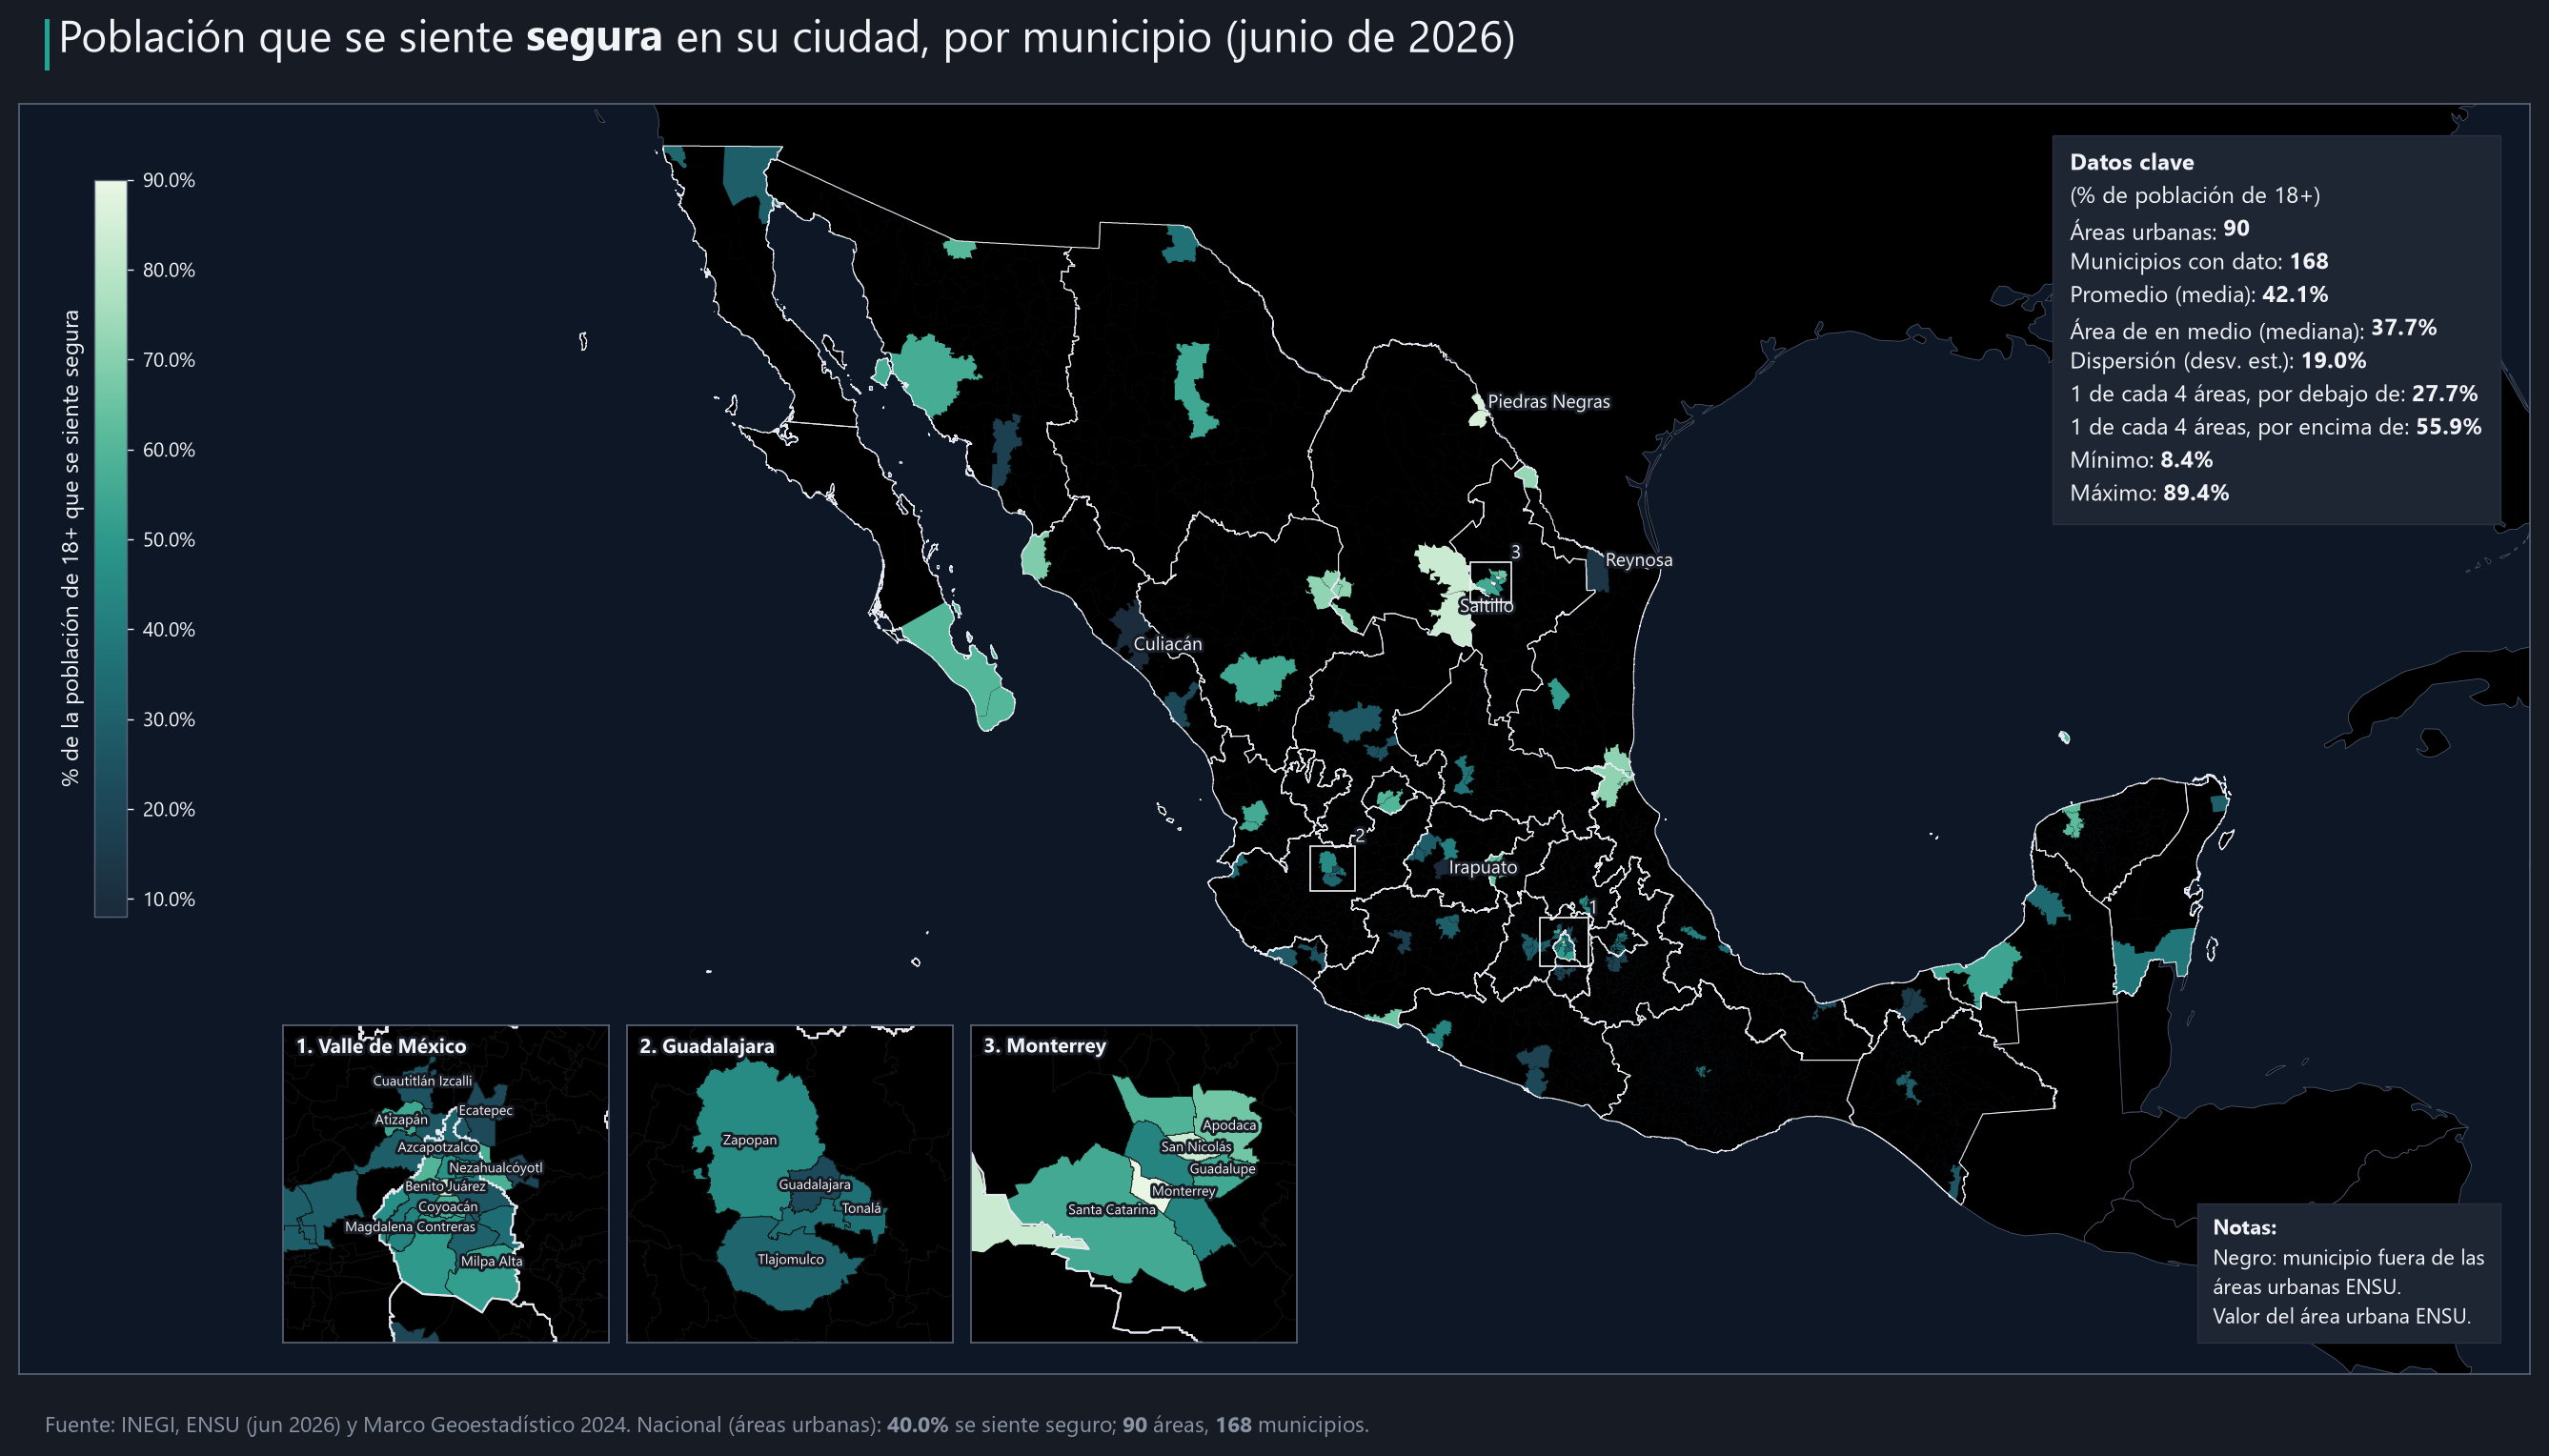

In [13]:
areas_seg = principal(seg)
charts.municipal_map(
    mun, ent, neighbors, dict(zip(seg.CVEGEO, seg.seguridad_pct)), areas_seg.seguridad_pct,
    [n("Población que se siente "), b("segura"), n(" en su ciudad, por municipio (junio de 2026)")],
    "% de población de 18+", "% de la población de 18+ que se siente segura", lambda v: f"{v:.1f}%",
    [n("Fuente: INEGI, ENSU (jun 2026) y Marco Geoestadístico 2024. Nacional (áreas urbanas): "), b("40.0%"),
     n(" se siente seguro; "), b(f"{areas_seg.area_urbana_ensu.nunique()}"), n(" áreas, "), b(f"{len(seg)}"), n(" municipios.")],
    CHARTS / "10_mapa_municipal_seguridad.png", insets(seg), labels=label_points(seg, "seguridad_pct"),
    n_mun=len(seg), note_lines=["Negro: municipio fuera de las", "áreas urbanas ENSU.", "Valor del área urbana ENSU."]); plt.show()

## 6. Página HTML (opcional)

Reporte web en formato de tablero (`docs/index.html`): indicadores, tarjetas y gráficas Plotly interactivas.

In [14]:
ent_coarse = [{"props": f["props"], "rings": [r for r in (geo._snap(x, 2500) for x in f["rings"]) if len(r) >= 4]} for f in ent]
geo_html = {"entidades": geo.to_geojson(ent_coarse)}
for key, table, col in [("mapa_costo", cost, "costo_canasta"), ("mapa_seguridad", seg, "seguridad_pct")]:
    feats = [{"props": mun_by_id[c]["props"], "rings": [geo._snap(r, 600) for r in mun_by_id[c]["rings"]]} for c in table.CVEGEO]
    geo_html[key] = {"geojson": geo.to_geojson(feats), "ids": table.CVEGEO.tolist(), "z": table[col].round(2).tolist(),
                     "text": [[mun_by_id[c]["props"]["NOMGEO"], a.rstrip("0123456789")] for c, a in zip(table.CVEGEO, table.area_urbana_ensu)]}
qty = CANDIDATOS.set_index("producto_normalizado").cantidad_canasta
pp = prices[prices.area_urbana_ensu.isin(res.area_urbana_ensu) & prices.producto_normalizado.isin(items)].copy()
pp["precio_mediana"] = pp.precio_mediana * pp.producto_normalizado.map(qty)
out = viz.interactive_html(res, pp, names, meta, geo_html, ROOT / "docs/index.html", disp=disp,
                           chains=pd.read_csv(PROC / "comparacion_cadenas.csv"), store=store)
print(out, f"{out.stat().st_size / 1e6:.1f} MB")

C:\Users\THINKPAD\Documents\Documentos\analisis economicos\20octubre26\mexico-costo-canasta\docs\index.html 2.7 MB
